# ME F321 Project — Fault Diagnosis of a Spacecraft Propulsion System

**Course:** ME F321 Data Mining in Mechanical Sciences

## Problem statement (summary)

A spacecraft propulsion system has four solenoid valves (SV1–SV4) and seven pressure sensors (P1–P7). For every test
*case*, the pressure at P1–P7 is recorded at **1 kHz for 1200 ms** while the valves are opened and closed three times.
Using these signals we must diagnose:

| Task | Question | Type | Training cases used |
|---|---|---|---|
| 1 | Is the case **normal** or **abnormal**? | Binary classification | all 177 |
| 2 | Is the abnormality a **bubble anomaly**, a **solenoid-valve fault** or an **unknown** anomaly? | Classification + novelty detection | 72 abnormal |
| 3 | Where is the bubble? (BV1, BP1–BP7) | 8-class classification | 24 bubble |
| 4 | Which solenoid valve failed? (SV1–SV4) | 4-class classification | 48 valve fault |
| 5 | What is the **opening ratio** (%) of the failed valve? | Regression | 48 valve fault |

**Main difficulty:** training data come from spacecraft 1, 2 and 3; the test data come from spacecraft 1 **and spacecraft 4,
which is never seen during training**. Every spacecraft behaves slightly differently, so a model that memorises
spacecraft-specific details will fail on spacecraft 4.

## Approach used in this notebook

1. **Data loading and quality checks** (Lab 3: missing values, duplicates, outliers).
2. **Exploratory analysis** in the time and frequency domain (Lab 2 plots, Lab 3 FFT / STFT).
3. **Pre-processing:** average the three valve cycles (noise reduction) and subtract a **spacecraft reference signal**
   (median signal of that spacecraft) to obtain a *residual* signal. The residual removes individual spacecraft differences.
4. **Feature extraction:** statistical features (mean, standard deviation, max, min, RMS — as in the Lab 8 bearing example)
   of the raw and residual signals in four physical phases of the cycle, plus FFT features.
5. **Feature analysis:** correlation, mutual information, ReliefF (Lab 4) and PCA (Lab 3).
6. **Validation:** *Leave-One-Spacecraft-Out* (LOSO) — train on two spacecraft, test on the third. This imitates the real
   test (an unseen spacecraft) much better than a random train/test split.
7. **Models** from Labs 6–8: Decision Tree, Random Forest, Gradient Boosting, Gaussian Naive Bayes, linear and RBF SVM, KNN.
   Regression versions are used for Task 5. A Lab-8-style Keras neural network is compared as well.
8. **Novelty detection** (distance to nearest known cases in PCA space) to catch *unknown* anomalies.
9. **Final hierarchical prediction** for the test set (Task 1 → Task 2 → Task 3 or Tasks 4/5) and a Bokeh dashboard (Lab 3).

## Step 1 — Import the required libraries

Most imports are the same ones used in the lab demos. The only additions are the **regression** versions of the lab models
(`RandomForestRegressor`, `GradientBoostingRegressor`, `SVR`, `KNeighborsRegressor`) and regression metrics, which are
needed because Task 5 asks for a continuous value (the valve opening ratio).

In [1]:
import os
import numpy as np                      # Arrays and numerical calculations
import pandas as pd                     # Tables and data inspection
import matplotlib.pyplot as plt         # Plotting
import seaborn as sns                   # Heatmaps
from IPython.display import display
from scipy.signal import stft           # Short-Time Fourier Transform (Lab 3)

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    pairwise_distances,
)

# Classifiers used in Labs 6, 7 and 8
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Regression versions of the same models (needed for Task 5 only)
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)

## Step 2 — Configuration

`DATA_DIR` must point to the folder that contains the `train` and `test` folders (see `data/README.md`).
All figures and the prediction files are written to `OUT_DIR`.

In [2]:
# -----------------------------------------------------
# Paths
# -----------------------------------------------------
DATA_DIR = 'data'   # folder with train/ and test/ (see data/README.md)
TRAIN_DIR = f'{DATA_DIR}/train/data'
TEST_DIR = f'{DATA_DIR}/test/data'

OUT_DIR = 'outputs'
FIG_DIR = f'{OUT_DIR}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

# -----------------------------------------------------
# Constants describing the experiment
# -----------------------------------------------------
FS = 1000                                   # Sampling frequency (Hz) -> 1 sample = 1 ms
N_SAMPLES = 1200                            # We keep 0-1199 ms (3 complete cycles of 400 ms)
CYCLE = 400                                 # The valves repeat the same open/close cycle every 400 ms
SENSORS = [f'P{i}' for i in range(1, 8)]    # Pressure sensors P1-P7
VALVES = ['SV1', 'SV2', 'SV3', 'SV4']       # Solenoid valves
BUBBLE_LOCS = ['BV1'] + [f'BP{i}' for i in range(1, 8)]   # Possible bubble locations
RS = 42                                     # random_state used everywhere (reproducibility)

COND_COLORS = {'normal': 'tab:green', 'bubble': 'tab:blue', 'valve': 'tab:red'}

def savefig(name):
    # Save the current figure so that it can be used in the report.
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

## Step 3 — Load the label files

`labels.xlsx` has a **two-row header**: the first row gives the group name (*Solenoid valves Opening Ratio /%*, *Bubble*) and
the second row gives the individual columns (SV1–SV4, BP1–BP7, BV1). We read both header rows and convert the sheet into one
clean table with the columns

`case, spacecraft, condition (normal / bubble / valve), bubble_loc, valve, ratio`.

In [3]:
lab_raw = pd.read_excel(f'{DATA_DIR}/train/labels.xlsx', header=[0, 1])
print('Shape of raw label sheet:', lab_raw.shape)
display(lab_raw.head())

Shape of raw label sheet: (177, 15)


Case#        Spacecraft#          Condition  \
  Unnamed: 0_level_1 Unnamed: 1_level_1 Unnamed: 2_level_1   
0                  1                  1             Normal   
1                  2                  1             Normal   
2                  3                  1             Normal   
3                  4                  1             Normal   
4                  5                  1             Normal   

  Solenoid valves Opening Ratio /%                Bubble                      \
                               SV1  SV2  SV3  SV4    BP1 BP2 BP3 BP4 BP5 BP6   
0                              100  100  100  100     No  No  No  No  No  No   
1                              100  100  100  100     No  No  No  No  No  No   
2                              100  100  100  100     No  No  No  No  No  No   
3                              100  100  100  100     No  No  No  No  No  No   
4                              100  100  100  100     No  No  No  No  No  No   

           
  BP7 BV1  
0  No  No  
1  No  No  
2  No  No  
3  No  No  
4  No  No

In [4]:
# -----------------------------------------------------
# Build a clean label table
# -----------------------------------------------------
sub_names = lab_raw.columns.get_level_values(1)          # second header row: SV1..SV4, BP1..BP7, BV1

train_labels = pd.DataFrame({
    'case': lab_raw.iloc[:, 0].astype(int),
    'spacecraft': lab_raw.iloc[:, 1].astype(int),
})

# Condition: Normal -> normal, Anomaly -> bubble, Fault -> solenoid-valve fault
condition_map = {'Normal': 'normal', 'Anomaly': 'bubble', 'Fault': 'valve'}
train_labels['condition'] = lab_raw.iloc[:, 2].map(condition_map)

# Valve opening ratios (100 % = healthy valve)
ratios = lab_raw.iloc[:, 3:7].astype(float)
ratios.columns = sub_names[3:7]

# Bubble location: the column that contains 'Yes'
bubble = lab_raw.iloc[:, 7:15] == 'Yes'
bubble.columns = sub_names[7:15]
train_labels['bubble_loc'] = [bubble.columns[row.values.argmax()] if row.any() else np.nan
                              for _, row in bubble.iterrows()]

# Failed valve = the valve whose opening ratio is below 100 %, and its opening ratio
train_labels['valve'] = [ratios.columns[row.values.argmin()] if row.min() < 100 else np.nan
                         for _, row in ratios.iterrows()]
train_labels['ratio'] = np.where(train_labels['valve'].notna(), ratios.min(axis=1), np.nan)

display(train_labels.head())

print('\nNumber of cases per condition and spacecraft:')
display(pd.crosstab(train_labels['condition'], train_labels['spacecraft'], margins=True))

print('Valve-fault cases: failed valve vs opening ratio')
display(pd.crosstab(train_labels['valve'], train_labels['ratio']))

print('Bubble cases per location:')
print(train_labels['bubble_loc'].value_counts().sort_index().to_dict())

,case,spacecraft,condition,bubble_loc,valve,ratio
0,1,1,normal,NaN,NaN,NaN
1,2,1,normal,NaN,NaN,NaN
2,3,1,normal,NaN,NaN,NaN
3,4,1,normal,NaN,NaN,NaN
4,5,1,normal,NaN,NaN,NaN



Number of cases per condition and spacecraft:


spacecraft,1,2,3,All
condition,,,,
bubble,8,8,8,24
normal,35,35,35,105
valve,16,16,16,48
All,59,59,59,177


Valve-fault cases: failed valve vs opening ratio


ratio,0.0,25.0,50.0,75.0
valve,,,,
SV1,3,3,3,3
SV2,3,3,3,3
SV3,3,3,3,3
SV4,3,3,3,3


Bubble cases per location:
{'BP1': 3, 'BP2': 3, 'BP3': 3, 'BP4': 3, 'BP5': 3, 'BP6': 3, 'BP7': 3, 'BV1': 3}


In [5]:
# Test label file: only the case number and the spacecraft number are given
test_labels = pd.read_excel(f'{DATA_DIR}/test/labels_spacecraft.xlsx', header=1)
test_labels.columns = ['case', 'spacecraft']
test_labels = test_labels.astype(int)

print('Number of test cases:', len(test_labels))
print('Test cases per spacecraft:', test_labels['spacecraft'].value_counts().sort_index().to_dict())
display(test_labels.head())

Number of test cases: 46
Test cases per spacecraft: {1: 23, 4: 23}


,case,spacecraft
0,178,1
1,179,1
2,180,1
3,181,1
4,182,1


## Step 4 — Load the pressure signals and check data quality

Each CSV file has a `TIME` column followed by `P1 ... P7`. We keep the first 1200 samples (0–1199 ms), which contain exactly
three valve cycles of 400 ms. All signals are stored in a NumPy array of shape **(number of cases, 7 sensors, 1200 samples)**.

Data-quality checks (as in Lab 3): missing values, record length, sampling interval, duplicate files and outliers.

In [6]:
def read_case(folder, case_no):
    # Read one CSV file and return (pressure array of shape (7, n), DataFrame).
    df = pd.read_csv(f'{folder}/Case{case_no:03d}.csv')
    return df[SENSORS].to_numpy().T, df

# Look at one file first
_, example = read_case(TRAIN_DIR, 1)
print('Columns:', list(example.columns))
print('Rows (samples):', len(example))
print('Sampling interval (ms):', round(example['TIME'].diff().median() * 1000, 3))
display(example.head())

Columns:

 ['TIME', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7']
Rows (samples): 1201
Sampling interval (ms): 1.0


,TIME,P1,P2,P3,P4,P5,P6,P7
0,0.000,2.0,2.0,2.0,2.0,2.0,2.0,2.0
1,0.001,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2,0.002,2.0,2.0,2.0,2.0,2.0,2.0,2.0
3,0.003,2.0,2.0,2.0,2.0,2.0,2.0,2.0
4,0.004,2.0,2.0,2.0,2.0,2.0,2.0,2.0


In [7]:
# -----------------------------------------------------
# Load all training and test cases
# -----------------------------------------------------
def load_all(folder, case_numbers):
    signals, quality = [], []
    for c in case_numbers:
        P, df = read_case(folder, c)
        quality.append({'case': c,
                        'n_samples': len(df),
                        'missing_values': int(df.isna().sum().sum())})
        signals.append(P[:, :N_SAMPLES])
    return np.stack(signals), pd.DataFrame(quality)

X_train, qc_train = load_all(TRAIN_DIR, train_labels['case'])
X_test, qc_test = load_all(TEST_DIR, test_labels['case'])

print('Training signals:', X_train.shape)
print('Test signals    :', X_test.shape)

Training signals: (177, 7, 1200)
Test signals    : (46, 7, 1200)


In [8]:
# -----------------------------------------------------
# Data-quality summary
# -----------------------------------------------------
for name, qc, X in [('train', qc_train, X_train), ('test', qc_test, X_test)]:
    dup_mask = pd.DataFrame(X.reshape(len(X), -1)).duplicated(keep=False)
    print(f'[{name}] missing values = {qc["missing_values"].sum()}, '
          f'record lengths = {sorted(qc["n_samples"].unique())}, '
          f'cases with an identical signal = {qc.loc[dup_mask.values, "case"].tolist()}')
print('Identical signals in different cases are kept: each case still needs its own prediction.')

# The downloaded test folder contains extra files such as 'Case179(1).csv'.
# Check whether they are just duplicate downloads of the original files.
extra = [f for f in os.listdir(TEST_DIR) if '(' in f]
identical = [f for f in extra
             if pd.read_csv(f'{TEST_DIR}/{f}').equals(pd.read_csv(f'{TEST_DIR}/{f.replace("(1)", "")}'))]
print(f'\nExtra "(1)" files in the test folder: {len(extra)}, identical to the original file: {len(identical)}')
print('-> They are duplicate downloads and are ignored (only the case numbers in labels_spacecraft.xlsx are used).')

[train] missing values = 0, record lengths = [np.int64(1201)], cases with an identical signal = []


[test] missing values = 0, record lengths = [np.int64(1201)], cases with an identical signal = [184, 200]
Identical signals in different cases are kept: each case still needs its own prediction.



Extra "(1)" files in the test folder: 16, identical to the original file: 16
-> They are duplicate downloads and are ignored (only the case numbers in labels_spacecraft.xlsx are used).


In [9]:
# -----------------------------------------------------
# Outlier screening with z-scores (Lab 3)
# -----------------------------------------------------
# One summary value per case and sensor: mean pressure over the whole record
case_means = pd.DataFrame(X_train.mean(axis=2), columns=SENSORS)
Z = (case_means - case_means.mean()) / case_means.std()

outlier_rows = (Z.abs() > 3).any(axis=1)
print('Cases with |z| > 3 on any sensor:', int(outlier_rows.sum()))
print(train_labels.loc[outlier_rows, 'condition'].value_counts())
print('\nThese "outliers" are real faults (not measurement errors), so they are NOT removed.')

Cases with |z| > 3 on any sensor: 17
condition
valve     14
bubble     3
Name: count, dtype: int64

These "outliers" are real faults (not measurement errors), so they are NOT removed.


## Step 5 — Exploratory data analysis

### 5.1 A typical normal case

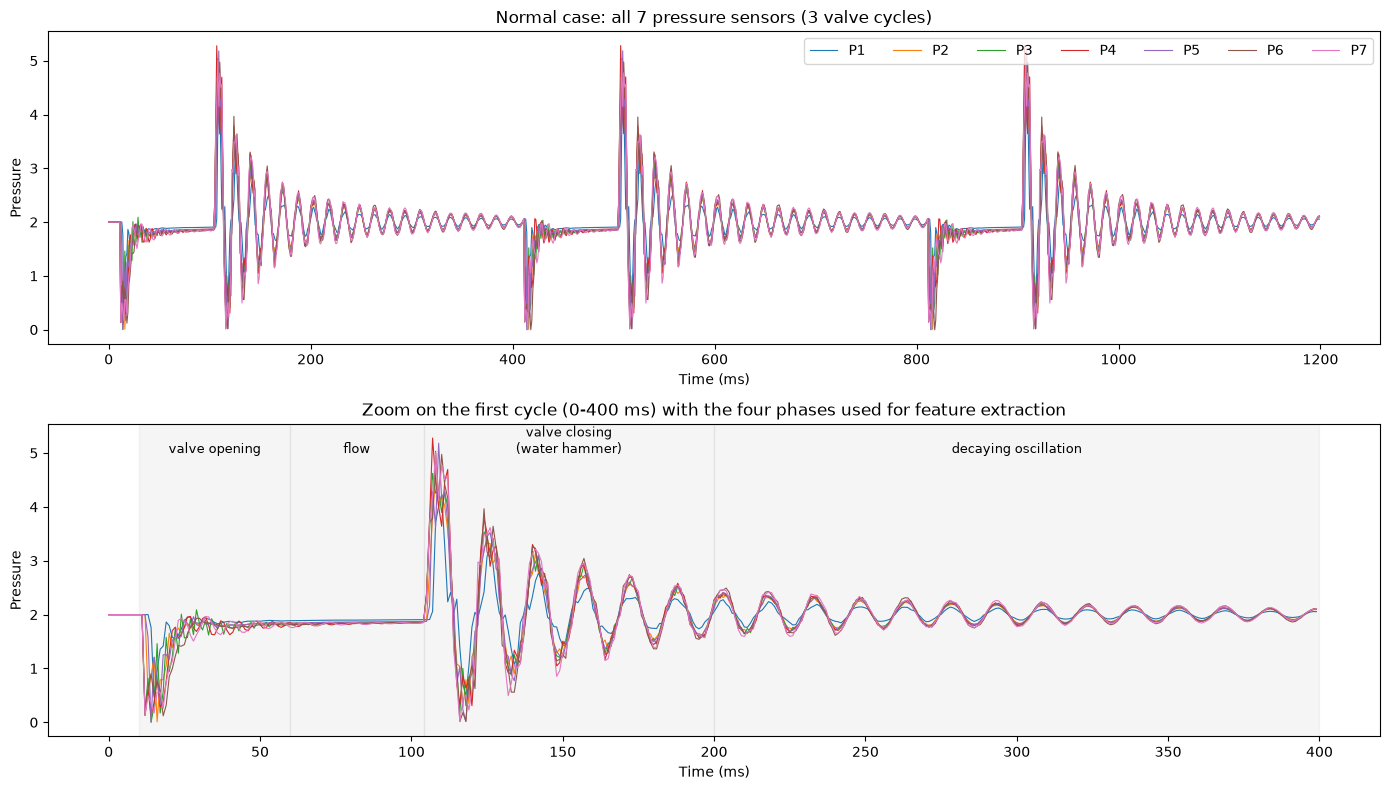

In [10]:
t = np.arange(N_SAMPLES)                       # time axis in ms
idx_normal = np.where(train_labels['condition'] == 'normal')[0]
x = X_train[idx_normal[0]]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for k, s in enumerate(SENSORS):
    axes[0].plot(t, x[k], lw=0.8, label=s)
axes[0].set_title('Normal case: all 7 pressure sensors (3 valve cycles)')
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Pressure')
axes[0].legend(ncol=7)

for k, s in enumerate(SENSORS):
    axes[1].plot(t[:CYCLE], x[k, :CYCLE], lw=0.8, label=s)
for name, (a, b) in {'valve opening': (10, 60), 'flow': (60, 104),
                     'valve closing\n(water hammer)': (104, 200), 'decaying oscillation': (200, 400)}.items():
    axes[1].axvspan(a, b, alpha=0.08, color='grey')
    axes[1].text((a + b) / 2, 5.0, name, ha='center', fontsize=9)
axes[1].set_title('Zoom on the first cycle (0-400 ms) with the four phases used for feature extraction')
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Pressure')
plt.tight_layout()
savefig('eda_normal_case')
plt.show()

**Observations**

* The valves **open at ≈ 11 ms** (sudden pressure drop) and **close at ≈ 105 ms**. Closing produces a strong *water-hammer*
  pressure spike followed by a decaying oscillation of ≈ 60 Hz.
* The same pattern repeats every **400 ms** (three cycles in 1200 ms).
* All sensors follow the same general shape but with small delays — the pressure wave travels through the pipes.

### 5.2 Normal vs bubble anomaly vs valve fault

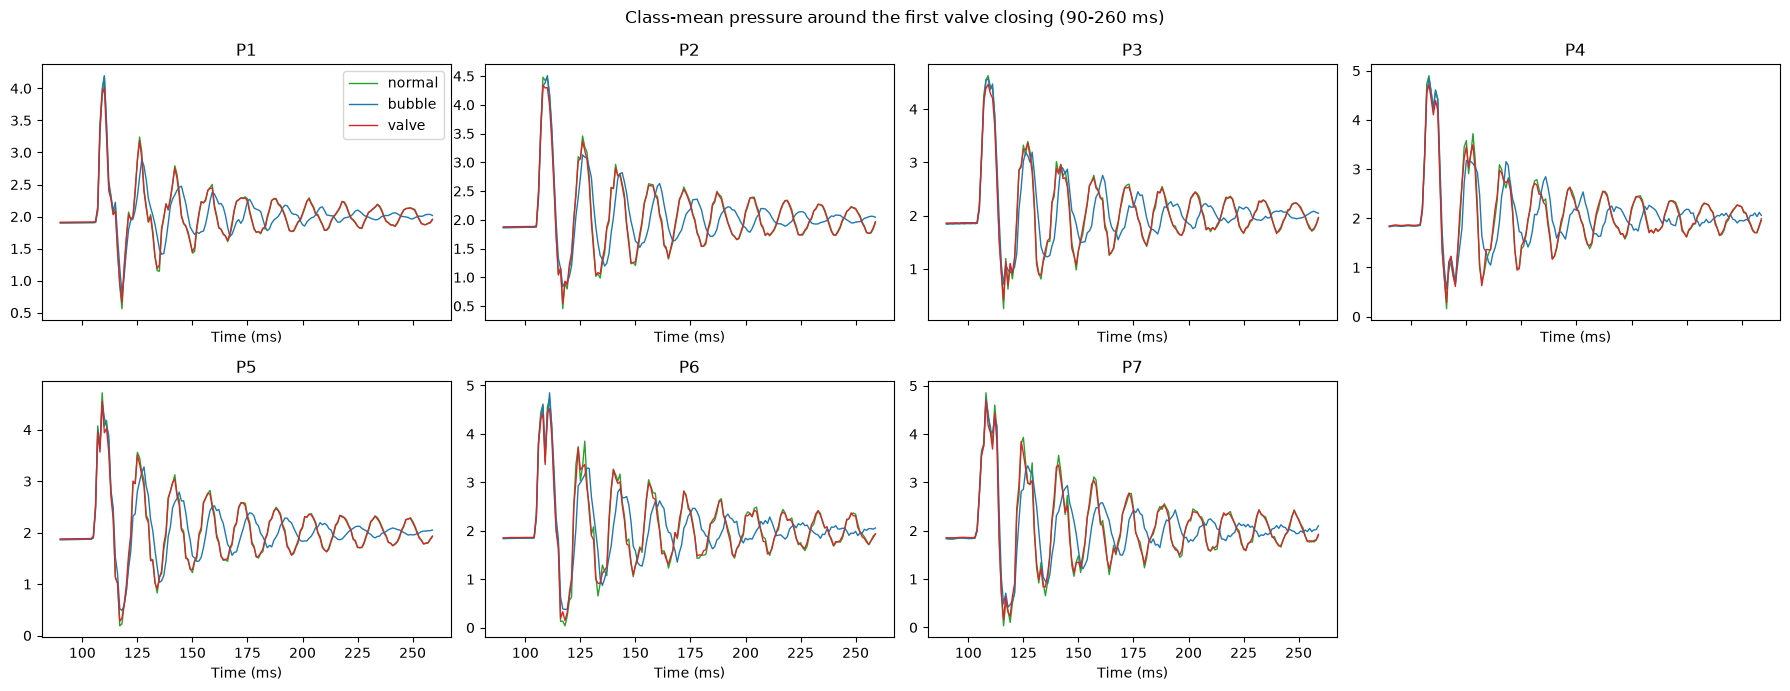

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for ax, (k, s) in zip(axes.ravel(), enumerate(SENSORS)):
    for cond, col in COND_COLORS.items():
        sel = train_labels['condition'] == cond
        ax.plot(t[90:260], X_train[sel, k, 90:260].mean(axis=0), color=col, lw=1, label=cond)
    ax.set_title(s)
    ax.set_xlabel('Time (ms)')
axes.ravel()[-1].axis('off')
axes[0, 0].legend()
fig.suptitle('Class-mean pressure around the first valve closing (90-260 ms)')
plt.tight_layout()
savefig('eda_class_means')
plt.show()

A **bubble** changes the speed of sound in the liquid, so the oscillation after valve closing gets a different frequency and
phase. A **valve fault** (partially open valve) changes the flow and therefore the size of the water hammer. Mild valve faults
(75 % opening) are very close to normal — this is the hardest part of the problem.

### 5.3 Individual differences between spacecraft

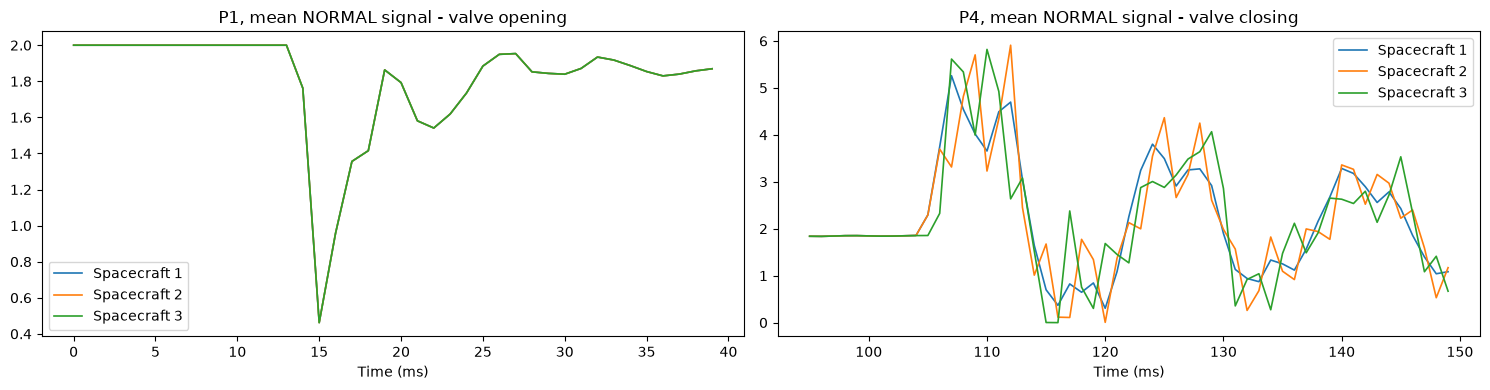

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for sc in sorted(train_labels['spacecraft'].unique()):
    sel = (train_labels['condition'] == 'normal') & (train_labels['spacecraft'] == sc)
    axes[0].plot(t[0:40], X_train[sel, 0, 0:40].mean(axis=0), lw=1.2, label=f'Spacecraft {sc}')
    axes[1].plot(t[95:150], X_train[sel, 3, 95:150].mean(axis=0), lw=1.2, label=f'Spacecraft {sc}')
axes[0].set_title('P1, mean NORMAL signal - valve opening')
axes[1].set_title('P4, mean NORMAL signal - valve closing')
for ax in axes:
    ax.set_xlabel('Time (ms)')
    ax.legend()
plt.tight_layout()
savefig('eda_spacecraft_differences')
plt.show()

Even for **normal** cases the closing transient differs between spacecraft, while the opening transient is identical. These
individual differences are of the same size as the effect of a mild fault, which is why we (i) validate with
Leave-One-Spacecraft-Out and (ii) subtract a spacecraft reference signal in Step 6.

### 5.4 Frequency domain: FFT and STFT (Lab 3 — data transformation)

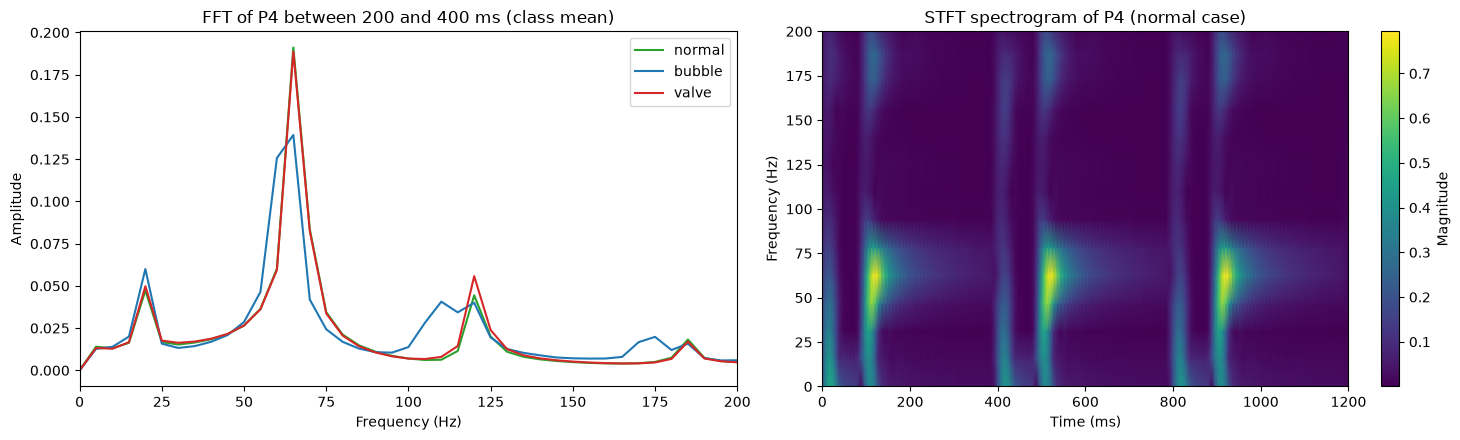

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# -----------------------------------------------------
# FFT of the decaying oscillation (200-400 ms), sensor P4
# -----------------------------------------------------
for cond, col in COND_COLORS.items():
    sel = np.where(train_labels['condition'] == cond)[0]
    seg = X_train[sel, 3, 200:400]
    seg = seg - seg.mean(axis=1, keepdims=True)          # remove the DC level
    N = seg.shape[1]
    fft_values = np.fft.fft(seg, axis=1)
    freq = np.fft.fftfreq(N, 1 / FS)
    axes[0].plot(freq[:N // 2], (2 / N * np.abs(fft_values[:, :N // 2])).mean(axis=0), color=col, label=cond)
axes[0].set_xlim(0, 200)
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('FFT of P4 between 200 and 400 ms (class mean)')
axes[0].legend()

# -----------------------------------------------------
# STFT spectrogram of one normal case
# -----------------------------------------------------
f, t_stft, Zxx = stft(x[3] - x[3].mean(), fs=FS, nperseg=64, noverlap=56)
im = axes[1].pcolormesh(t_stft * 1000, f, np.abs(Zxx), shading='gouraud')
axes[1].set_ylim(0, 200)
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('STFT spectrogram of P4 (normal case)')
plt.colorbar(im, ax=axes[1], label='Magnitude')
plt.tight_layout()
savefig('eda_fft_stft')
plt.show()

The dominant oscillation is at about 60 Hz. Bubbles shift this peak (lower speed of sound → lower frequency), so the
**dominant frequency and its amplitude** are used as features.

## Step 6 — Pre-processing

### 6.1 Average the three valve cycles
The three cycles are almost identical, so averaging them reduces random noise without losing information.

In [14]:
def cycle_average(X):
    # (cases, 7, 1200) -> (cases, 7, 3, 400) -> mean over the 3 cycles -> (cases, 7, 400)
    return X.reshape(len(X), len(SENSORS), N_SAMPLES // CYCLE, CYCLE).mean(axis=2)

C_train = cycle_average(X_train)
C_test = cycle_average(X_test)
print('Cycle-averaged training signals:', C_train.shape)

# How similar are the three cycles of one normal case?
cycles = X_train[idx_normal[0]].reshape(7, 3, CYCLE)
print('Mean |cycle1 - cycle2| =', np.abs(cycles[:, 0] - cycles[:, 1]).mean().round(4))
print('Mean |cycle2 - cycle3| =', np.abs(cycles[:, 1] - cycles[:, 2]).mean().round(4))

Cycle-averaged training signals: (177, 7, 400)
Mean |cycle1 - cycle2| = 0.0156
Mean |cycle2 - cycle3| = 0.0008


### 6.2 Spacecraft reference signal and residual signals

For every spacecraft we compute a **reference signal = sample-wise median of all its cycle-averaged signals**. Because most
cases are normal, the median is a good estimate of the spacecraft's normal behaviour, and it is not affected by the minority
of faulty cases.

The **residual** = signal − reference of its own spacecraft describes *how much this case deviates from its own spacecraft*.
This removes individual spacecraft differences.

* Training spacecraft 1, 2, 3 → reference from their training cases.
* Test spacecraft 1 → the same reference as in training.
* Test spacecraft 4 (never seen) → reference from its own 23 test cases (no labels are needed, so this is allowed).

During Leave-One-Spacecraft-Out validation the held-out spacecraft also uses the median of its own cases, so the validation
copies exactly what happens to spacecraft 4.

In [15]:
def spacecraft_references(C, spacecraft):
    # Median cycle signal of every spacecraft -> dict {spacecraft: (7, 400) array}
    return {sc: np.median(C[spacecraft == sc], axis=0) for sc in np.unique(spacecraft)}

def residuals(C, spacecraft, refs):
    return np.stack([C[i] - refs[sc] for i, sc in enumerate(spacecraft)])

sc_train = train_labels['spacecraft'].to_numpy()
sc_test = test_labels['spacecraft'].to_numpy()

ref_train = spacecraft_references(C_train, sc_train)

# Test: use the training reference when the spacecraft is known, otherwise the median of its own test cases
ref_test = {}
for sc in np.unique(sc_test):
    if sc in ref_train:
        ref_test[sc] = ref_train[sc]
        print(f'Test spacecraft {sc}: reference taken from training data')
    else:
        ref_test[sc] = np.median(C_test[sc_test == sc], axis=0)
        print(f'Test spacecraft {sc}: unseen -> reference = median of its {np.sum(sc_test == sc)} test cases')

R_train = residuals(C_train, sc_train, ref_train)
R_test = residuals(C_test, sc_test, ref_test)

Test spacecraft 1: reference taken from training data
Test spacecraft 4: unseen -> reference = median of its 23 test cases


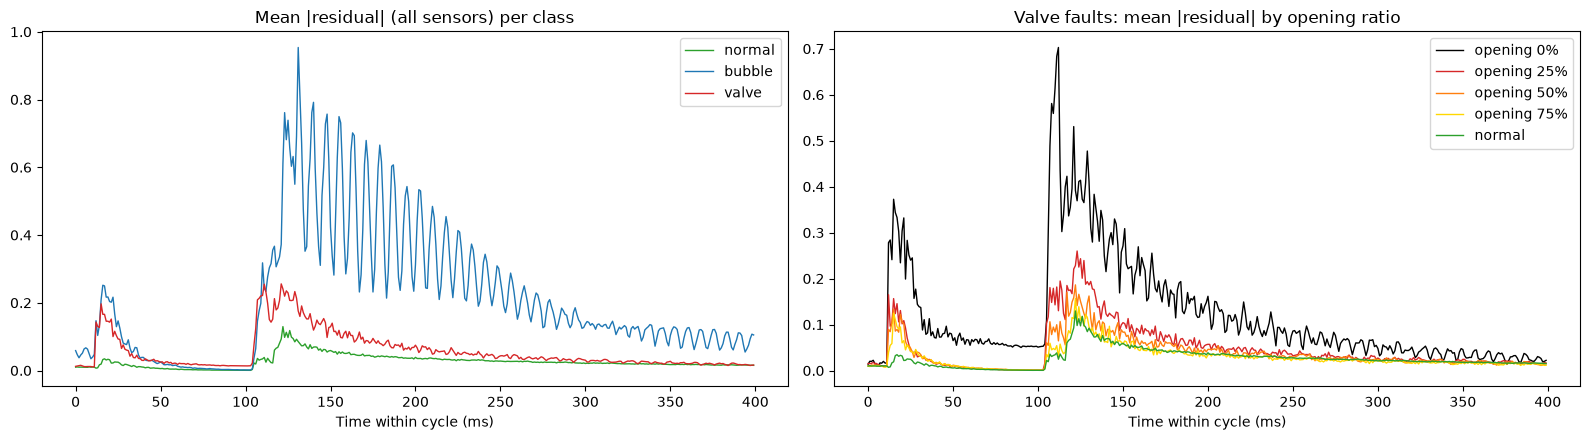

In [16]:
# -----------------------------------------------------
# Mean absolute residual over time for each class
# -----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for cond, col in COND_COLORS.items():
    sel = train_labels['condition'] == cond
    axes[0].plot(np.arange(CYCLE), np.abs(R_train[sel]).mean(axis=(0, 1)), color=col, lw=1, label=cond)
axes[0].set_title('Mean |residual| (all sensors) per class')

valve_cases = train_labels['condition'] == 'valve'
for r, col in zip([0, 25, 50, 75], ['black', 'tab:red', 'tab:orange', 'gold']):
    sel = valve_cases & (train_labels['ratio'] == r)
    axes[1].plot(np.arange(CYCLE), np.abs(R_train[sel]).mean(axis=(0, 1)), color=col, lw=1, label=f'opening {r}%')
sel = train_labels['condition'] == 'normal'
axes[1].plot(np.arange(CYCLE), np.abs(R_train[sel]).mean(axis=(0, 1)), color='tab:green', lw=1, label='normal')
axes[1].set_title('Valve faults: mean |residual| by opening ratio')
for ax in axes:
    ax.set_xlabel('Time within cycle (ms)')
    ax.legend()
plt.tight_layout()
savefig('residuals_by_class')
plt.show()

After subtracting the reference, normal cases have a residual close to zero, bubbles give a large residual after valve
closing, and valve faults give a residual that grows as the opening ratio decreases (0 % largest, 75 % smallest).

## Step 7 — Feature extraction

Each case (7 sensors × 400 samples) is converted into one row of features. For each sensor and each of the four phases of the
cycle (opening 10–60 ms, flow 60–104 ms, closing 104–200 ms, oscillation tail 200–400 ms) we compute five statistical
features — **mean, standard deviation, max, min and RMS** — both of the raw signal and of the residual signal.

| Group | Features | Physical meaning |
|---|---|---|
| Raw statistics | mean, std, max, min, RMS per sensor and phase | pressure levels, water-hammer size |
| Residual statistics | the same five features of the residual | deviation from the spacecraft's normal behaviour |
| Frequency (FFT) | dominant frequency and its amplitude of the 200–400 ms oscillation | speed of sound → **bubbles** |
| Residual energy share | RMS of the residual of each sensor divided by the sum over sensors | which sensor is closest to the fault → **location** |

In [17]:
SEGMENTS = {'open': (10, 60), 'flow': (60, 104), 'close': (104, 200), 'tail': (200, 400)}

def basic_stats(x, prefix):
    # Five statistical features of a 1-D signal segment (Lab 8 style)
    return {f'{prefix}_mean': np.mean(x),
            f'{prefix}_std': np.std(x),
            f'{prefix}_max': np.max(x),
            f'{prefix}_min': np.min(x),
            f'{prefix}_rms': np.sqrt(np.mean(x ** 2))}

def fft_peak(x, n_fft=2048):
    # Dominant frequency (Hz) and its amplitude. Zero padding to n_fft gives a finer frequency grid.
    x = x - np.mean(x)
    amp = 2 / len(x) * np.abs(np.fft.fft(x * np.hanning(len(x)), n_fft))[:n_fft // 2]
    freq = np.fft.fftfreq(n_fft, 1 / FS)[:n_fft // 2]
    i = np.argmax(amp)
    return freq[i], amp[i]

def extract_features(cycle, resid):
    f = {}
    for k, s in enumerate(SENSORS):
        for seg, (a, b) in SEGMENTS.items():
            f.update(basic_stats(cycle[k, a:b], f'{s}_{seg}_raw'))
            f.update(basic_stats(resid[k, a:b], f'{s}_{seg}_res'))
        f[f'{s}_tail_domfreq'], f[f'{s}_tail_domamp'] = fft_peak(cycle[k, 200:400])
        f[f'{s}_res_energy'] = np.sqrt(np.mean(resid[k] ** 2))
    total = sum(f[f'{s}_res_energy'] for s in SENSORS)
    for s in SENSORS:
        f[f'{s}_res_share'] = f[f'{s}_res_energy'] / (total + 1e-12)
    return f

F_train = pd.DataFrame([extract_features(C_train[i], R_train[i]) for i in range(len(C_train))])
F_test = pd.DataFrame([extract_features(C_test[i], R_test[i]) for i in range(len(C_test))])

# Two feature sets that will be compared
RAW_COLS = [c for c in F_train.columns if '_raw' in c or '_dom' in c]   # no spacecraft normalisation
RES_COLS = [c for c in F_train.columns if '_res' in c or '_dom' in c]   # residual (spacecraft-normalised) features

print('Feature matrix (train):', F_train.shape, '| test:', F_test.shape)
print('Raw feature set     :', len(RAW_COLS), 'features')
print('Residual feature set:', len(RES_COLS), 'features')
print('Missing values in features:', int(F_train.isna().sum().sum()), '(train),', int(F_test.isna().sum().sum()), '(test)')
display(F_train[RES_COLS].head())

Feature matrix (train): (177, 308) | test: (46, 308)
Raw feature set     : 154 features
Residual feature set: 168 features
Missing values in features: 0 (train), 0 (test)


,P1_open_res_mean,P1_open_res_std,P1_open_res_max,P1_open_res_min,P1_open_res_rms,P1_flow_res_mean,P1_flow_res_std,P1_flow_res_max,P1_flow_res_min,P1_flow_res_rms,P1_close_res_mean,P1_close_res_std,P1_close_res_max,P1_close_res_min,P1_close_res_rms,...,P7_tail_res_mean,P7_tail_res_std,P7_tail_res_max,P7_tail_res_min,P7_tail_res_rms,P7_tail_domfreq,P7_tail_domamp,P7_res_energy,P1_res_share,P2_res_share,P3_res_share,P4_res_share,P5_res_share,P6_res_share,P7_res_share
0,0.000012,0.000196,0.000732,-0.000478,0.000197,-4.631056e-06,0.000012,0.000017,-0.000052,0.000013,-0.000158,0.010400,0.034552,-0.032060,0.010402,...,-0.000082,0.017636,0.040519,-0.053048,0.017636,66.40625,0.113915,0.040392,0.037450,0.081220,0.096265,0.090276,0.085520,0.316153,0.293115
1,0.000013,0.000129,0.000361,-0.000357,0.000130,-4.070234e-06,0.000022,0.000044,-0.000123,0.000022,0.000096,0.007902,0.047853,-0.021053,0.007903,...,-0.002510,0.072685,0.156699,-0.156151,0.072728,66.40625,0.113860,0.093212,0.019360,0.044640,0.127129,0.124878,0.034011,0.188588,0.461395
2,-0.000040,0.000138,0.000203,-0.000430,0.000144,-3.913848e-07,0.000018,0.000039,-0.000052,0.000018,0.000403,0.005970,0.034886,-0.019986,0.005984,...,0.001592,0.071657,0.176351,-0.169144,0.071675,66.40625,0.113598,0.092293,0.017141,0.048362,0.086085,0.088080,0.073064,0.152900,0.534367
3,-0.000012,0.000090,0.000204,-0.000292,0.000091,-1.472613e-06,0.000014,0.000057,-0.000037,0.000014,0.000244,0.007326,0.034883,-0.027010,0.007330,...,-0.000643,0.028544,0.066568,-0.079924,0.028552,66.40625,0.114096,0.038341,0.027900,0.052568,0.130613,0.125036,0.044134,0.325571,0.294179
4,-0.000027,0.000120,0.000267,-0.000335,0.000123,-3.836211e-07,0.000012,0.000019,-0.000039,0.000012,0.000355,0.007289,0.028246,-0.023831,0.007297,...,-0.000481,0.021542,0.057357,-0.061564,0.021547,66.40625,0.114013,0.030714,0.029378,0.069417,0.151274,0.165340,0.064211,0.273626,0.246753


## Step 8 — Feature analysis

### 8.1 Redundancy: correlation between features (Lab 4)

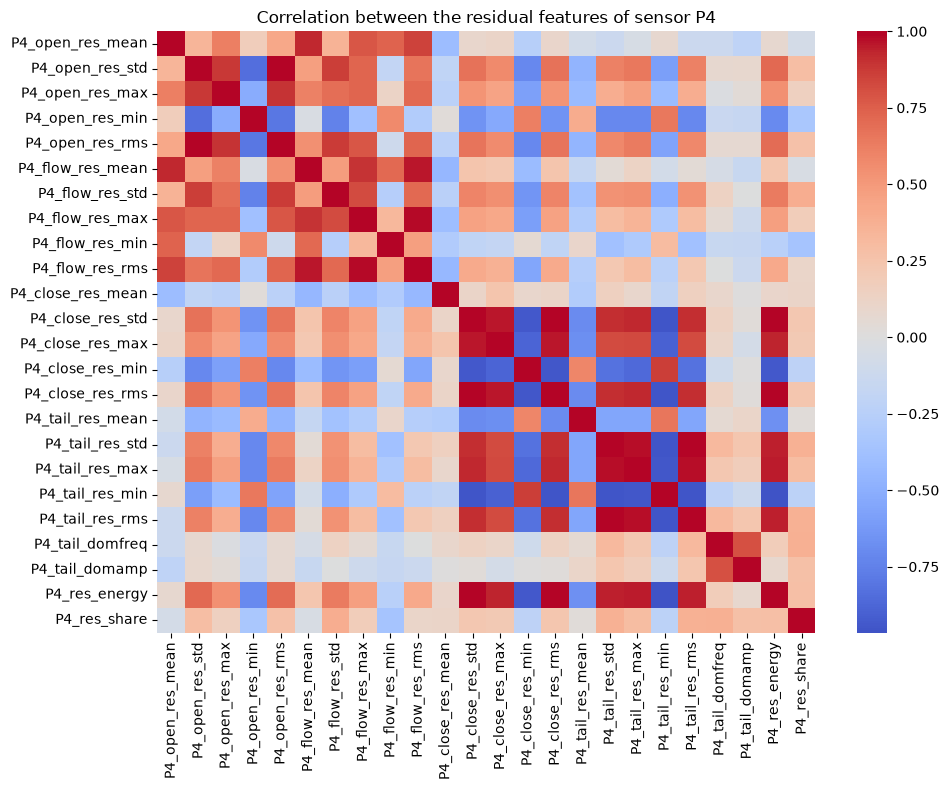

Feature pairs with |correlation| > 0.95: 546 out of 14028
Many features are redundant (e.g. std and RMS of a residual). Tree ensembles handle this well;
mutual information below shows which features carry the most information for each task.


In [18]:
corr = F_train[RES_COLS].corr()

plt.figure(figsize=(10, 8))
p4_cols = [c for c in RES_COLS if c.startswith('P4_')]
sns.heatmap(F_train[p4_cols].corr(), cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
plt.title('Correlation between the residual features of sensor P4')
plt.tight_layout()
savefig('feature_correlation_P4')
plt.show()

# Count highly correlated pairs
threshold = 0.95
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
n_pairs = int((upper > threshold).sum().sum())
print(f'Feature pairs with |correlation| > {threshold}: {n_pairs} out of {int(upper.notna().sum().sum())}')
print('Many features are redundant (e.g. std and RMS of a residual). Tree ensembles handle this well;')
print('mutual information below shows which features carry the most information for each task.')

### 8.2 Relevance: mutual information for every task (Lab 4)

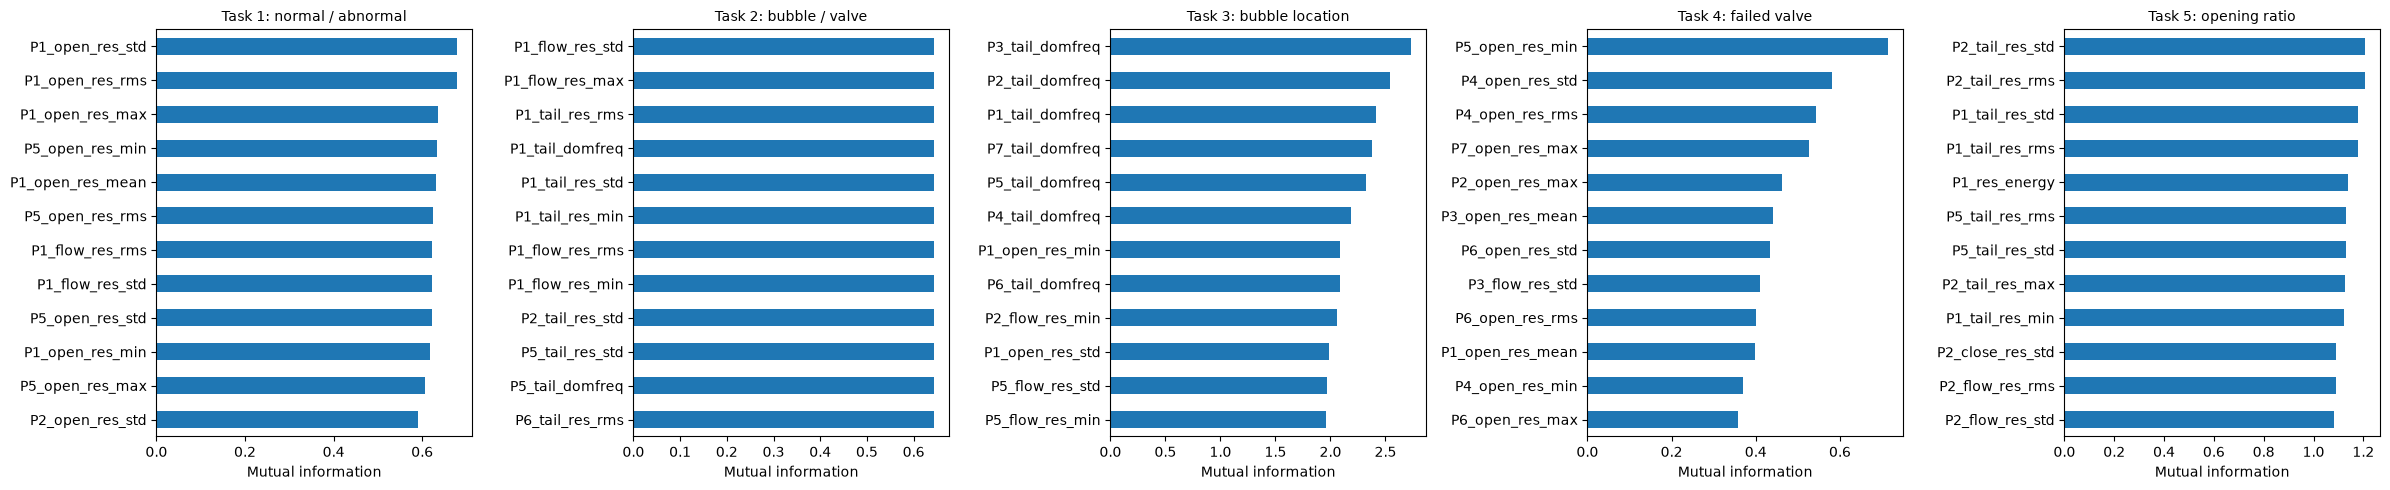

In [19]:
is_abn = (train_labels['condition'] != 'normal').to_numpy()
is_bub = (train_labels['condition'] == 'bubble').to_numpy()
is_val = (train_labels['condition'] == 'valve').to_numpy()

# Target vectors of the five tasks
y1 = np.where(is_abn, 'abnormal', 'normal')
y2 = train_labels.loc[is_abn, 'condition'].to_numpy()
y3 = train_labels.loc[is_bub, 'bubble_loc'].to_numpy()
y4 = train_labels.loc[is_val, 'valve'].to_numpy()
y5 = train_labels.loc[is_val, 'ratio'].to_numpy()

def mi_ranking(F, y, top=12):
    scores = mutual_info_classif(F, y, random_state=RS)
    return pd.Series(scores, index=F.columns).sort_values(ascending=False).head(top)

MI = {
    'Task 1: normal / abnormal': mi_ranking(F_train[RES_COLS], y1),
    'Task 2: bubble / valve': mi_ranking(F_train.loc[is_abn, RES_COLS], y2),
    'Task 3: bubble location': mi_ranking(F_train.loc[is_bub, RES_COLS], y3),
    'Task 4: failed valve': mi_ranking(F_train.loc[is_val, RES_COLS], y4),
    'Task 5: opening ratio': mi_ranking(F_train.loc[is_val, RES_COLS], y5.astype(int).astype(str)),
}

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, (task, s) in zip(axes, MI.items()):
    s[::-1].plot.barh(ax=ax)
    ax.set_title(task, fontsize=10)
    ax.set_xlabel('Mutual information')
plt.tight_layout()
savefig('mutual_information')
plt.show()

### 8.3 ReliefF ranking for the bubble location (Lab 4)
ReliefF uses distances, so the features are first scaled to [0, 1] with `MinMaxScaler` (as in the lab). If `skrebate` is not
installed, this step is skipped (`pip install skrebate`).

In [20]:
try:
    from skrebate import ReliefF
    X_bub_scaled = MinMaxScaler().fit_transform(F_train.loc[is_bub, RES_COLS])
    relief = ReliefF(n_neighbors=2)            # only 3 cases per location -> 2 nearest hits
    relief.fit(X_bub_scaled, y3)
    relief_scores = pd.DataFrame({'Feature': RES_COLS, 'ReliefF_Score': relief.feature_importances_})
    relief_scores = relief_scores.sort_values('ReliefF_Score', ascending=False)
    display(relief_scores.head(10))
except ImportError:
    print('skrebate is not installed -> ReliefF skipped')

,Feature,ReliefF_Score
20,P1_tail_domfreq,0.928571
112,P5_tail_domfreq,0.928571
66,P3_tail_domfreq,0.928571
43,P2_tail_domfreq,0.928571
158,P7_tail_domfreq,0.851190
135,P6_tail_domfreq,0.845238
89,P4_tail_domfreq,0.767857
98,P5_flow_res_std,0.678814
101,P5_flow_res_rms,0.675875
29,P2_flow_res_std,0.659527


### 8.4 PCA visualisation: raw vs residual features (Lab 3)

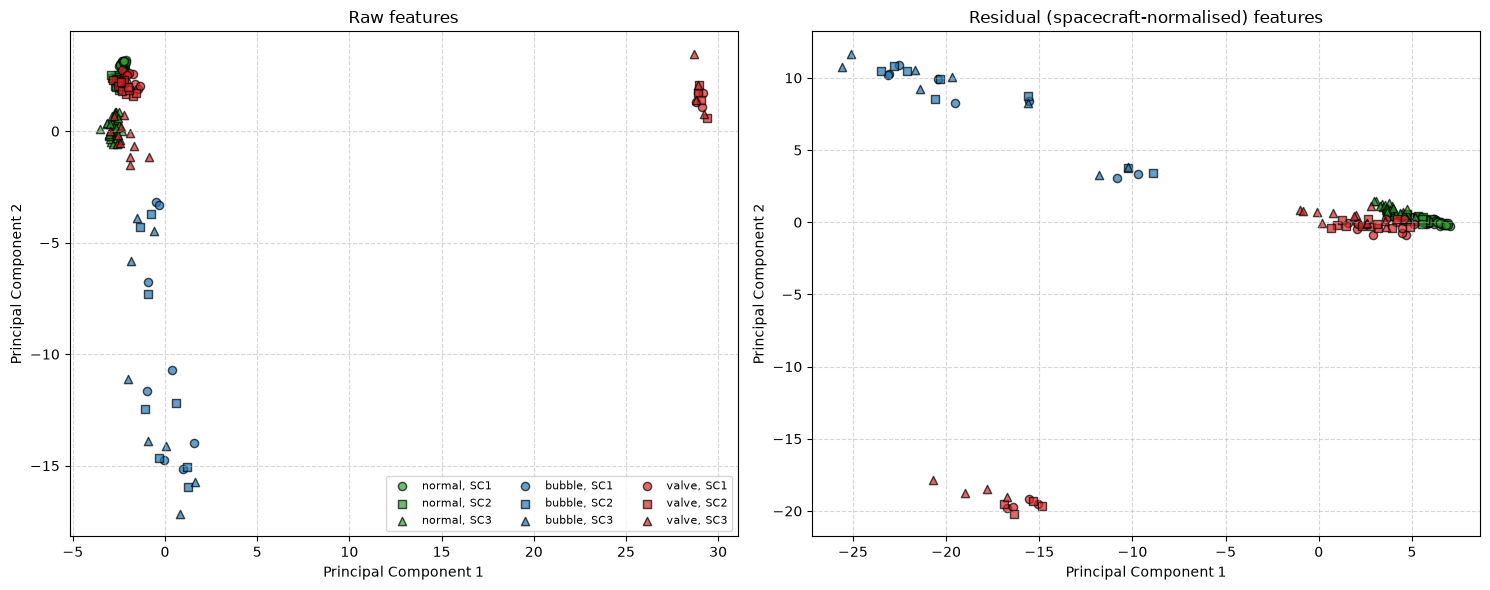

In [21]:
markers = {1: 'o', 2: 's', 3: '^'}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (title, cols) in zip(axes, [('Raw features', RAW_COLS), ('Residual (spacecraft-normalised) features', RES_COLS)]):
    X_pca = PCA(n_components=2, random_state=RS).fit_transform(StandardScaler().fit_transform(F_train[cols]))
    for cond, col in COND_COLORS.items():
        for sc, mk in markers.items():
            m = (train_labels['condition'] == cond).to_numpy() & (sc_train == sc)
            ax.scatter(X_pca[m, 0], X_pca[m, 1], c=col, marker=mk, s=35, alpha=0.7, edgecolors='k',
                       label=f'{cond}, SC{sc}')
    ax.set_title(title)
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=8, ncol=3)
plt.tight_layout()
savefig('pca_raw_vs_residual')
plt.show()

With raw features the points are grouped partly by **spacecraft** (marker shape). With residual features the grouping is by
**condition** (colour), which is exactly what we want for a spacecraft that has never been seen.

## Step 9 — Validation strategy and model zoo

### 9.1 Leave-One-Spacecraft-Out (LOSO) validation
For each spacecraft *s* in {1, 2, 3}: fit the scaler and the model on the other two spacecraft and predict spacecraft *s*.
Every training case is predicted exactly once by a model that has never seen its spacecraft. The scaler is fitted inside the
loop (training part only) to avoid information leakage.

In [22]:
def get_classifiers():
    # The classifiers from Labs 6, 7 and 8
    return {
        'Random Forest':     RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=RS),
        'SVM (linear)':      SVC(kernel='linear', C=1),
        'SVM (RBF)':         SVC(kernel='rbf', C=10, gamma='scale'),
        'KNN (k=3)':         KNeighborsClassifier(n_neighbors=3),
        'Decision Tree':     DecisionTreeClassifier(max_depth=5, random_state=RS),
        'Gaussian NB':       GaussianNB(),
    }

def get_regressors():
    return {
        'Random Forest':     RandomForestRegressor(n_estimators=300, random_state=RS, n_jobs=-1),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, max_depth=2, random_state=RS),
        'SVR (RBF)':         SVR(kernel='rbf', C=100, epsilon=1.0),
        'KNN (k=3)':         KNeighborsRegressor(n_neighbors=3, weights='distance'),
    }

def loso_predict(model, F, y, groups, regression=False):
    # Leave-One-Spacecraft-Out predictions for every case
    F = np.asarray(F)
    y_pred = np.zeros(len(y)) if regression else np.empty(len(y), dtype=object)
    for sc in np.unique(groups):
        train, test = groups != sc, groups == sc
        scaler = StandardScaler().fit(F[train])
        model.fit(scaler.transform(F[train]), y[train])
        y_pred[test] = model.predict(scaler.transform(F[test]))
    return y_pred

def compare_classifiers(F, y, groups):
    # Evaluate all classifiers with LOSO. Returns a results table and the predictions of every model.
    rows, preds = [], {}
    for name, model in get_classifiers().items():
        y_pred = loso_predict(model, F, y, groups)
        preds[name] = y_pred
        fold_acc = [accuracy_score(y[groups == sc], y_pred[groups == sc]) for sc in np.unique(groups)]
        rows.append({'Model': name,
                     'Accuracy': accuracy_score(y, y_pred),
                     'Macro F1': f1_score(y, y_pred, average='macro'),
                     'Worst-spacecraft accuracy': min(fold_acc)})
    # Stable sort: when two models tie, the one listed first in get_classifiers() is preferred
    results = pd.DataFrame(rows).sort_values(['Macro F1', 'Worst-spacecraft accuracy'],
                                             ascending=False, kind='mergesort').reset_index(drop=True)
    return results, preds

def plot_comparison(results, metric, title, fname, xlim=(0, 1.05)):
    ax = results.sort_values(metric).plot.barh(x='Model', y=metric, legend=False, figsize=(7, 3.5), color='tab:blue')
    ax.set_title(title)
    ax.set_xlabel(metric)
    if xlim:
        ax.set_xlim(*xlim)
    plt.tight_layout()
    savefig(fname)
    plt.show()

def plot_cm(y, y_pred, labels, title, fname):
    ConfusionMatrixDisplay(confusion_matrix(y, y_pred, labels=labels), display_labels=labels).plot(
        cmap='Blues', values_format='d')
    plt.title(title)
    plt.tight_layout()
    savefig(fname)
    plt.show()

RESULTS = {}     # collected for the summary and the dashboard

### 9.2 Why LOSO? Random split vs LOSO (Task 1, raw features)
A random 70/30 split (as in the labs) puts cases of the *same* spacecraft in both the training and the test part, so it
does not measure how well a model works on a **new** spacecraft.

In [23]:
idx_tr, idx_te = train_test_split(np.arange(len(y1)), test_size=0.30, random_state=RS, stratify=y1)

rows = []
for name, model in get_classifiers().items():
    # (a) random split
    scaler = StandardScaler().fit(F_train.loc[idx_tr, RAW_COLS])
    model.fit(scaler.transform(F_train.loc[idx_tr, RAW_COLS]), y1[idx_tr])
    f1_random = f1_score(y1[idx_te], model.predict(scaler.transform(F_train.loc[idx_te, RAW_COLS])), average='macro')
    # (b) Leave-One-Spacecraft-Out
    f1_loso = f1_score(y1, loso_predict(model, F_train[RAW_COLS], y1, sc_train), average='macro')
    rows.append({'Model': name, 'Macro F1 (random 70/30 split)': f1_random, 'Macro F1 (LOSO)': f1_loso})

cv_compare = pd.DataFrame(rows)
display(cv_compare.round(3))

,Model,Macro F1 (random 70/30 split),Macro F1 (LOSO)
0,Random Forest,0.981,0.721
1,Gradient Boosting,0.981,0.750
2,SVM (linear),1.000,0.740
3,SVM (RBF),0.981,0.660
4,KNN (k=3),0.900,0.857
5,Decision Tree,0.981,0.739
6,Gaussian NB,0.981,0.320


The random split gives a higher (optimistic) score for most models. LOSO is the honest estimate for spacecraft 4, so **all
model selection below uses LOSO**.

### 9.3 Raw vs residual features (LOSO, Tasks 1–4)

In [24]:
task_data = {
    'Task 1': (np.ones(len(y1), bool), y1),
    'Task 2': (is_abn, y2),
    'Task 3': (is_bub, y3),
    'Task 4': (is_val, y4),
}

rows = []
for fs_name, cols in [('raw', RAW_COLS), ('residual', RES_COLS)]:
    for task, (mask, y) in task_data.items():
        res, _ = compare_classifiers(F_train.loc[mask, cols], y, sc_train[mask])
        rows.append({'Feature set': fs_name, 'Task': task,
                     'Best model': res.loc[0, 'Model'], 'Best Macro F1': res.loc[0, 'Macro F1'],
                     'Mean Macro F1 (all models)': res['Macro F1'].mean()})
fs_compare = pd.DataFrame(rows)
display(fs_compare.pivot(index='Task', columns='Feature set',
                         values=['Best Macro F1', 'Mean Macro F1 (all models)']).round(3))

best_set = fs_compare.groupby('Feature set')['Mean Macro F1 (all models)'].mean().idxmax()
FEATURES = RES_COLS if best_set == 'residual' else RAW_COLS
print('Feature set used from now on:', best_set, f'({len(FEATURES)} features)')

Best Macro F1          Mean Macro F1 (all models)         
Feature set           raw residual                        raw residual
Task                                                                  
Task 1              0.857      1.0                      0.684    0.927
Task 2              1.000      1.0                      0.932    0.987
Task 3              1.000      1.0                      0.890    0.888
Task 4              1.000      1.0                      0.749    0.863

Feature set used from now on: residual (168 features)


### 9.4 Random split vs LOSO again, now with residual features (Tasks 1–4)
Step 9.2 showed that, with raw features, the random split is far too optimistic. Here the same comparison is repeated on
the **residual** features. One 70/30 split leaves only 7–53 test cases per task, so the random-split score is averaged
over 10 different splits (seeds 0–9); the worst of the 10 is shown too.

In [25]:
rows = []
for task, (mask, y) in task_data.items():
    F_t, sc_t = F_train.loc[mask, RES_COLS].reset_index(drop=True), sc_train[mask]
    for name, model in get_classifiers().items():
        f1_rnd = []
        for seed in range(10):
            tr, te = train_test_split(np.arange(len(y)), test_size=0.30, random_state=seed, stratify=y)
            scaler = StandardScaler().fit(F_t.loc[tr])
            model.fit(scaler.transform(F_t.loc[tr]), y[tr])
            f1_rnd.append(f1_score(y[te], model.predict(scaler.transform(F_t.loc[te])), average='macro'))
        f1_loso = f1_score(y, loso_predict(model, F_t, y, sc_t), average='macro')
        rows.append({'Task': task, 'Model': name, 'Random split (mean of 10)': np.mean(f1_rnd),
                     'Random split (worst of 10)': np.min(f1_rnd), 'LOSO': f1_loso})

res_split = pd.DataFrame(rows)
display(res_split.pivot(index='Model', columns='Task', values=['Random split (mean of 10)', 'LOSO']).round(3))
display(res_split[res_split['Model'] == 'Random Forest'].round(3))

Random split (mean of 10)                        LOSO  \
Task                                 Task 1 Task 2 Task 3 Task 4 Task 1   
Model                                                                     
Decision Tree                         0.992  1.000  0.584  0.822  1.000   
Gaussian NB                           1.000  0.965  0.821  0.553  0.607   
Gradient Boosting                     0.994  1.000  1.000  0.831  1.000   
KNN (k=3)                             0.926  0.989  0.779  0.637  0.988   
Random Forest                         1.000  1.000  0.983  0.957  1.000   
SVM (RBF)                             0.980  0.965  0.848  0.844  0.931   
SVM (linear)                          0.982  0.982  0.892  0.980  0.965   

                                        
Task              Task 2 Task 3 Task 4  
Model                                   
Decision Tree      1.000  0.711  0.830  
Gaussian NB        0.940  0.877  0.750  
Gradient Boosting  1.000  1.000  0.878  
KNN (k=3)          1.000  0.835  0.767  
Random Forest      1.000  1.000  1.000  
SVM (RBF)          0.984  0.877  0.857  
SVM (linear)       0.984  0.919  0.958

,Task,Model,Random split (mean of 10),Random split (worst of 10),LOSO
0,Task 1,Random Forest,1.000,1.000,1.0
7,Task 2,Random Forest,1.000,1.000,1.0
14,Task 3,Random Forest,0.983,0.833,1.0
21,Task 4,Random Forest,0.957,0.703,1.0


With residual features the random split and LOSO now give **similar** scores: the residuals no longer carry which
spacecraft a case came from, so a model that does well on a random split also does well on an unseen spacecraft.

* On Tasks 3 and 4 the random split is sometimes *lower* than LOSO. Its test part holds only 8 (bubble location) or 15
  (failed valve) cases, so a single mistake moves the score a lot. LOSO predicts every case exactly once.
* Gaussian Naive Bayes is the exception on Task 1 (≈ 1.00 random, 0.61 LOSO): it still picks up spacecraft-specific patterns.
* Random Forest is at or near 1.00 under both schemes and is the only model with LOSO = 1.00 on all four tasks.

## Step 10 — Task 1: Normal vs abnormal

### 10.1 Supervised classifiers (LOSO)

,Model,Accuracy,Macro F1,Worst-spacecraft accuracy
0,Random Forest,1.000,1.000,1.000
1,Gradient Boosting,1.000,1.000,1.000
2,Decision Tree,1.000,1.000,1.000
3,KNN (k=3),0.989,0.988,0.983
4,SVM (linear),0.966,0.965,0.915
5,SVM (RBF),0.932,0.931,0.831
6,Gaussian NB,0.621,0.607,0.407


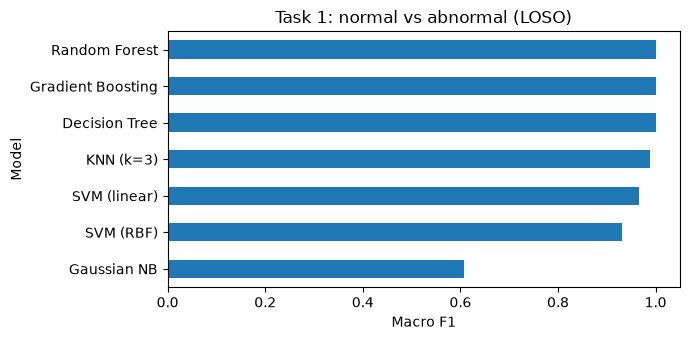

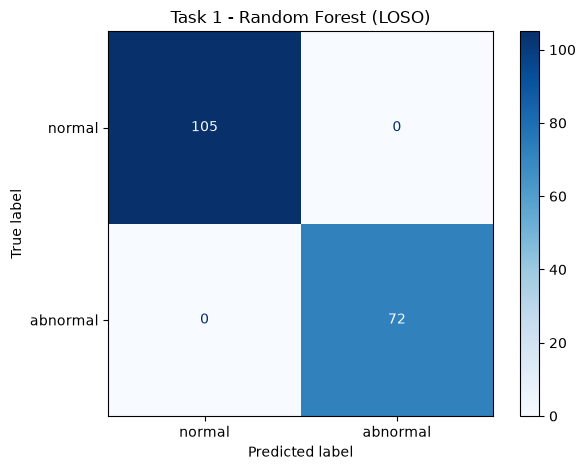

              precision    recall  f1-score   support

    abnormal       1.00      1.00      1.00        72
      normal       1.00      1.00      1.00       105

    accuracy                           1.00       177
   macro avg       1.00      1.00      1.00       177
weighted avg       1.00      1.00      1.00       177



In [26]:
F1_ = F_train[FEATURES]
res1, preds1 = compare_classifiers(F1_, y1, sc_train)
display(res1.round(3))
plot_comparison(res1, 'Macro F1', 'Task 1: normal vs abnormal (LOSO)', 't1_comparison')

best1 = res1.loc[0, 'Model']
plot_cm(y1, preds1[best1], ['normal', 'abnormal'], f'Task 1 - {best1} (LOSO)', 't1_confusion_matrix')
print(classification_report(y1, preds1[best1]))
RESULTS['Task 1'] = dict(res=res1, y=y1, y_pred=preds1[best1], labels=['normal', 'abnormal'], best=best1)

### 10.2 Novelty check for *unknown* anomalies
A classifier only knows the two anomaly types it has seen. The test set may contain an **unknown** anomaly that the classifier
could wrongly call "normal". We therefore also build a simple **normal-behaviour model**:

1. Standardise the features and project them with PCA (10 components), using **normal** training cases only.
2. Novelty score of a case = mean Euclidean distance to its 3 nearest normal cases (`pairwise_distances`, Lab 4).
3. The threshold is the **largest LOSO score of a normal case**, so no normal training case would be flagged.

Final Task-1 rule: *abnormal* if the classifier says abnormal **or** the novelty score is above the threshold.

,Rule,Accuracy,Macro F1
0,Random Forest only,1.000,1.000
1,Novelty score only,0.864,0.849
2,Classifier OR novelty,1.000,1.000


Abnormal training cases caught by the novelty score alone: 67%


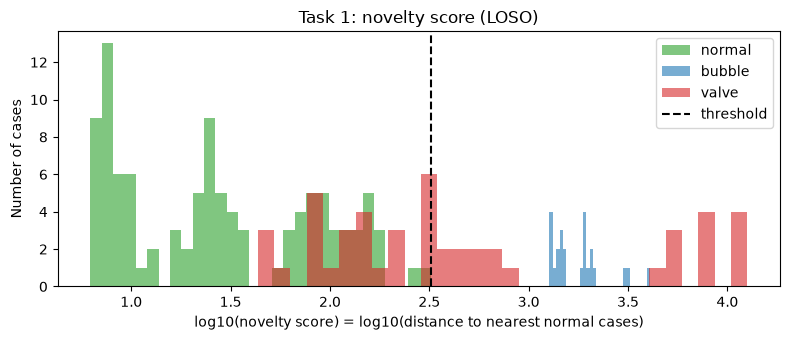

In [27]:
def fit_novelty(F_ref, n_components=10):
    # Normal-behaviour (or known-class) model: scaler + PCA fitted on the reference cases only
    F_ref = np.asarray(F_ref)
    scaler = StandardScaler().fit(F_ref)
    pca = PCA(n_components=min(n_components, len(F_ref) - 1), random_state=RS).fit(scaler.transform(F_ref))
    return scaler, pca, pca.transform(scaler.transform(F_ref))

def novelty_score(model, F, k=3):
    # Mean distance to the k nearest reference cases in the PCA space
    scaler, pca, Z_ref = model
    Z = pca.transform(scaler.transform(np.asarray(F)))
    d = np.sort(pairwise_distances(Z, Z_ref), axis=1)
    return d[:, :k].mean(axis=1)

def loso_novelty(F, ref_mask, groups):
    # For every spacecraft: fit on the reference cases of the OTHER spacecraft, score the held-out spacecraft
    F = np.asarray(F)
    scores = np.zeros(len(F))
    for sc in np.unique(groups):
        model = fit_novelty(F[ref_mask & (groups != sc)])
        scores[groups == sc] = novelty_score(model, F[groups == sc])
    return scores

nov1 = loso_novelty(F1_, ~is_abn, sc_train)
THR1 = nov1[~is_abn].max()
nov_pred = np.where(nov1 > THR1, 'abnormal', 'normal')
or_pred = np.where((preds1[best1] == 'abnormal') | (nov_pred == 'abnormal'), 'abnormal', 'normal')

t1_rules = pd.DataFrame([
    {'Rule': f'{best1} only', 'Accuracy': accuracy_score(y1, preds1[best1]), 'Macro F1': f1_score(y1, preds1[best1], average='macro')},
    {'Rule': 'Novelty score only', 'Accuracy': accuracy_score(y1, nov_pred), 'Macro F1': f1_score(y1, nov_pred, average='macro')},
    {'Rule': 'Classifier OR novelty', 'Accuracy': accuracy_score(y1, or_pred), 'Macro F1': f1_score(y1, or_pred, average='macro')},
])
display(t1_rules.round(3))
print(f'Abnormal training cases caught by the novelty score alone: {np.mean(nov1[is_abn] > THR1):.0%}')

plt.figure(figsize=(8, 3.5))
for cond, col in COND_COLORS.items():
    m = (train_labels['condition'] == cond).to_numpy()
    plt.hist(np.log10(nov1[m]), bins=30, alpha=0.6, color=col, label=cond)
plt.axvline(np.log10(THR1), color='k', ls='--', label='threshold')
plt.xlabel('log10(novelty score) = log10(distance to nearest normal cases)')
plt.ylabel('Number of cases')
plt.title('Task 1: novelty score (LOSO)')
plt.legend()
plt.tight_layout()
savefig('t1_novelty')
plt.show()

## Step 11 — Task 2: Bubble anomaly vs solenoid-valve fault vs unknown

### 11.1 Known classes (abnormal cases only, LOSO)

,Model,Accuracy,Macro F1,Worst-spacecraft accuracy
0,Random Forest,1.000,1.000,1.000
1,Gradient Boosting,1.000,1.000,1.000
2,KNN (k=3),1.000,1.000,1.000
3,Decision Tree,1.000,1.000,1.000
4,SVM (linear),0.986,0.984,0.958
5,SVM (RBF),0.986,0.984,0.958
6,Gaussian NB,0.944,0.940,0.917


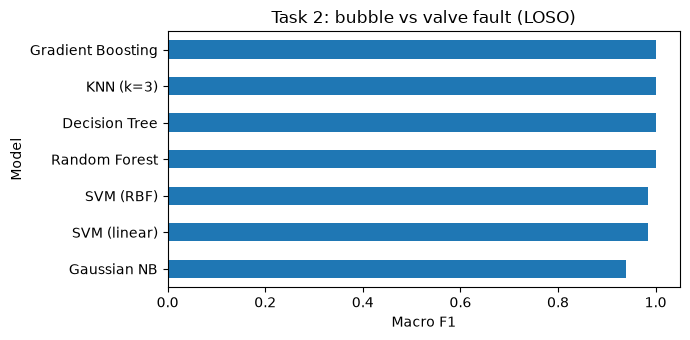

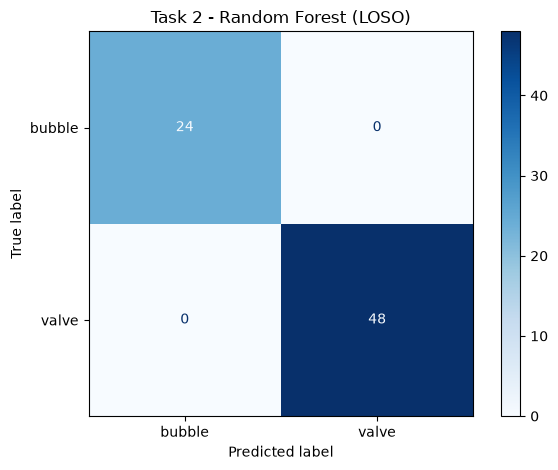

In [28]:
F2_, g2 = F_train.loc[is_abn, FEATURES], sc_train[is_abn]
res2, preds2 = compare_classifiers(F2_, y2, g2)
display(res2.round(3))
plot_comparison(res2, 'Macro F1', 'Task 2: bubble vs valve fault (LOSO)', 't2_comparison')

best2 = res2.loc[0, 'Model']
plot_cm(y2, preds2[best2], ['bubble', 'valve'], f'Task 2 - {best2} (LOSO)', 't2_confusion_matrix')
RESULTS['Task 2'] = dict(res=res2, y=y2, y_pred=preds2[best2], labels=['bubble', 'valve'], best=best2)

### 11.2 Detecting an *unknown* anomaly
No unknown anomaly exists in the training data, so we **simulate** one: hide one known class (e.g. all bubble cases), fit the
novelty model on the remaining class only, and check how many hidden cases receive a score above the threshold.

The final rule for the test set: an abnormal case is **unknown** if its novelty score with respect to *all* known abnormal
training cases is above the 97.5th percentile of the LOSO scores of the known abnormal cases.

In [29]:
known_all = np.ones(len(y2), bool)
nov2 = loso_novelty(F2_, known_all, g2)
THR2 = np.percentile(nov2, 97.5)
print(f'Known abnormal cases wrongly called "unknown" (LOSO): {np.mean(nov2 > THR2):.1%}')

rows = []
for hidden in ['bubble', 'valve']:
    known = y2 != hidden
    s_known = loso_novelty(F2_, known, g2)                    # LOSO scores w.r.t. the known class
    thr = np.percentile(s_known[known], 97.5)
    s_hidden = novelty_score(fit_novelty(F2_[known]), F2_[~known])
    rows.append({'Class pretended to be unknown': hidden,
                 'Hidden cases detected as unknown': f'{np.mean(s_hidden > thr):.0%}',
                 'Known cases wrongly flagged': f'{np.mean(s_known[known] > thr):.0%}'})
display(pd.DataFrame(rows))

Known abnormal cases wrongly called "unknown" (LOSO): 2.8%


,Class pretended to be unknown,Hidden cases detected as unknown,Known cases wrongly flagged
0,bubble,100%,4%
1,valve,31%,4%


A completely new kind of anomaly (simulated by hiding the bubbles) is detected well. Hiding the valve faults is harder because
mild valve faults look almost normal — they are close to *everything*. This is an honest limitation of the method.

## Step 12 — Task 3: Bubble location (8 classes)
Only 24 cases (3 per location, one per spacecraft), so each LOSO fold has just 2 examples per class.

,Model,Accuracy,Macro F1,Worst-spacecraft accuracy
0,Random Forest,1.000,1.000,1.000
1,Gradient Boosting,1.000,1.000,1.000
2,SVM (linear),0.917,0.919,0.875
3,SVM (RBF),0.875,0.877,0.750
4,Gaussian NB,0.875,0.877,0.750
5,KNN (k=3),0.833,0.835,0.750
6,Decision Tree,0.708,0.711,0.500


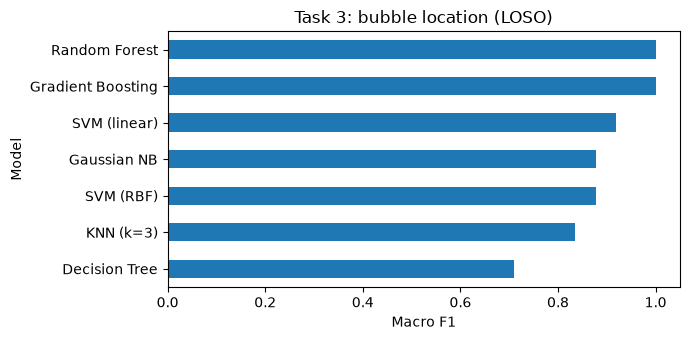

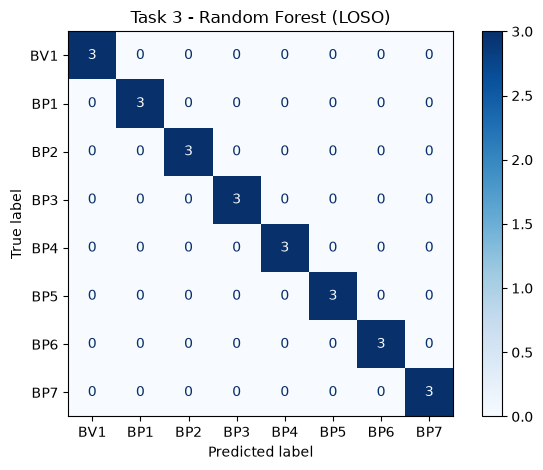

In [30]:
F3_, g3 = F_train.loc[is_bub, FEATURES], sc_train[is_bub]
res3, preds3 = compare_classifiers(F3_, y3, g3)
display(res3.round(3))
plot_comparison(res3, 'Macro F1', 'Task 3: bubble location (LOSO)', 't3_comparison')

best3 = res3.loc[0, 'Model']
plot_cm(y3, preds3[best3], BUBBLE_LOCS, f'Task 3 - {best3} (LOSO)', 't3_confusion_matrix')
RESULTS['Task 3'] = dict(res=res3, y=y3, y_pred=preds3[best3], labels=BUBBLE_LOCS, best=best3)

## Step 13 — Task 4: Which solenoid valve failed (4 classes)

,Model,Accuracy,Macro F1,Worst-spacecraft accuracy
0,Random Forest,1.000,1.000,1.000
1,SVM (linear),0.958,0.958,0.875
2,Gradient Boosting,0.875,0.878,0.750
3,SVM (RBF),0.854,0.857,0.750
4,Decision Tree,0.833,0.830,0.688
5,KNN (k=3),0.771,0.767,0.750
6,Gaussian NB,0.750,0.750,0.688


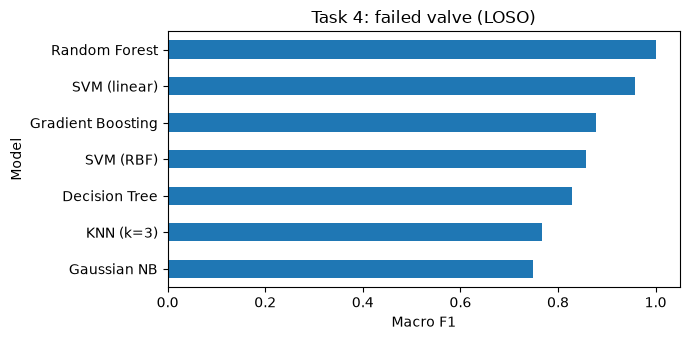

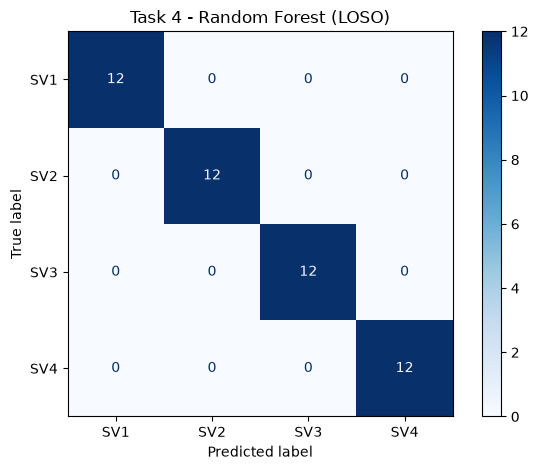

In [31]:
F4_, g4 = F_train.loc[is_val, FEATURES], sc_train[is_val]
res4, preds4 = compare_classifiers(F4_, y4, g4)
display(res4.round(3))
plot_comparison(res4, 'Macro F1', 'Task 4: failed valve (LOSO)', 't4_comparison')

best4 = res4.loc[0, 'Model']
plot_cm(y4, preds4[best4], VALVES, f'Task 4 - {best4} (LOSO)', 't4_confusion_matrix')
RESULTS['Task 4'] = dict(res=res4, y=y4, y_pred=preds4[best4], labels=VALVES, best=best4)

## Step 14 — Task 5: Opening ratio of the failed valve (regression)

The failed valve is added as four 0/1 (one-hot) columns: the true valve during training, the *predicted* valve (Task 4) for
the test set. The training ratios are only 0, 25, 50 and 75 %, while a real fault can have any ratio, so the predictions are
clipped to the physical range 0–100 %.

,Model,MAE (%),RMSE (%),R2
0,Gradient Boosting,5.278,8.779,0.901
1,Random Forest,5.628,8.152,0.915
2,KNN (k=3),9.365,13.001,0.784
3,SVR (RBF),10.392,13.011,0.783


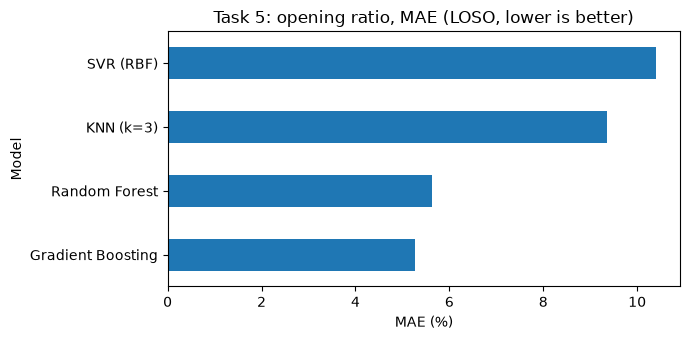

In [32]:
def add_valve_onehot(F, valves):
    onehot = pd.DataFrame({v: (np.asarray(valves) == v).astype(float) for v in VALVES}, index=F.index)
    return pd.concat([F, onehot], axis=1)

F5_ = add_valve_onehot(F4_, y4)

rows, preds5 = [], {}
for name, model in get_regressors().items():
    y_pred = np.clip(loso_predict(model, F5_, y5, g4, regression=True), 0, 100)
    preds5[name] = y_pred
    rows.append({'Model': name,
                 'MAE (%)': mean_absolute_error(y5, y_pred),
                 'RMSE (%)': np.sqrt(mean_squared_error(y5, y_pred)),
                 'R2': r2_score(y5, y_pred)})
res5 = pd.DataFrame(rows).sort_values('MAE (%)').reset_index(drop=True)
display(res5.round(3))
plot_comparison(res5, 'MAE (%)', 'Task 5: opening ratio, MAE (LOSO, lower is better)', 't5_comparison', xlim=None)
best5 = res5.loc[0, 'Model']

### 14.1 Hyper-parameter tuning with `GridSearchCV` (Lab 6) using the LOSO folds
`GridSearchCV` accepts a list of (train indices, test indices) pairs as `cv`, so we can give it the three LOSO folds directly.
Random Forest is scale-invariant, so no scaler is needed here.

In [33]:
loso_folds = [(np.where(g4 != sc)[0], np.where(g4 == sc)[0]) for sc in np.unique(g4)]

param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 5, 10],
    'max_features': ['sqrt', 0.3, 1.0],
}
grid5 = GridSearchCV(RandomForestRegressor(random_state=RS, n_jobs=-1), param_grid=param_grid,
                     cv=loso_folds, scoring='neg_mean_absolute_error')
grid5.fit(F5_, y5)
print('Best parameters:', grid5.best_params_)
print(f'LOSO MAE of the tuned Random Forest: {-grid5.best_score_:.2f} %')
print(f'LOSO MAE of the best untuned model ({best5}): {res5.loc[0, "MAE (%)"]:.2f} %')

# Use the tuned forest if it is better than the best untuned model
USE_TUNED_RF = -grid5.best_score_ < res5.loc[0, 'MAE (%)']
if USE_TUNED_RF:
    best5 = 'Random Forest (tuned)'
    y_pred_tuned = np.zeros(len(y5))
    for tr, te in loso_folds:
        y_pred_tuned[te] = RandomForestRegressor(random_state=RS, n_jobs=-1, **grid5.best_params_).fit(
            F5_.iloc[tr], y5[tr]).predict(F5_.iloc[te])
    preds5[best5] = np.clip(y_pred_tuned, 0, 100)
print('Final Task 5 model:', best5)

Best parameters: {'max_depth': None, 'max_features': 0.3, 'n_estimators': 100}
LOSO MAE of the tuned Random Forest: 5.47 %
LOSO MAE of the best untuned model (Gradient Boosting): 5.28 %
Final Task 5 model: Gradient Boosting


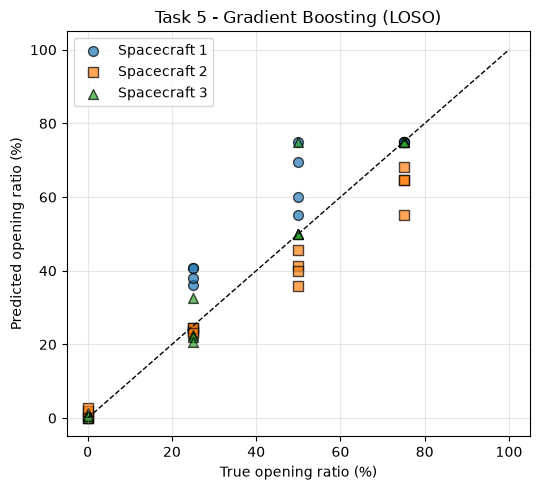

,mean,max
true ratio,,
0.0,0.60,2.83
25.0,6.41,15.78
50.0,10.16,25.00
75.0,3.94,19.74


In [34]:
plt.figure(figsize=(5.5, 5))
for sc, mk in markers.items():
    m = g4 == sc
    plt.scatter(y5[m], preds5[best5][m], marker=mk, s=50, alpha=0.7, edgecolors='k', label=f'Spacecraft {sc}')
plt.plot([0, 100], [0, 100], 'k--', lw=1)
plt.xlabel('True opening ratio (%)')
plt.ylabel('Predicted opening ratio (%)')
plt.title(f'Task 5 - {best5} (LOSO)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
savefig('t5_scatter')
plt.show()

# Error per true ratio level
err = pd.DataFrame({'true ratio': y5, 'abs error': np.abs(y5 - preds5[best5])})
display(err.groupby('true ratio')['abs error'].agg(['mean', 'max']).round(2))
RESULTS['Task 5'] = dict(res=res5, y=y5, y_pred=preds5[best5], best=best5)

## Step 15 — Neural network (ANN, Lab 8)

Can a neural network do as well as the classical models? We train a small Keras / TensorFlow network
(input → 64 neurons → 32 neurons → output), written like the Lab 8 bearing-fault network (`Sequential`, `Dense`, Adam,
softmax output), on the same residual features and with the same Leave-One-Spacecraft-Out folds. The training curves
(loss and accuracy per epoch) can be inspected as in Lab 8.

**Computational cost:** the dataset is tiny (at most 177 cases × 168 features), so no GPU is needed. The network needs
roughly half a minute per LOSO fold on a laptop CPU (TensorFlow has a fixed overhead per training step, and we run
200 epochs), i.e. a few minutes for all five tasks. The real limitation is the **small number of training cases**, not
computing power.

### 15.1 Neural network with Keras / TensorFlow (Lab 8 style)

The network is built as in Lab 8:

* `Dense(64, relu)` → `Dropout(0.2)` → `Dense(32, relu)` → `Dense(n_classes, softmax)` for classification, or a single
  linear output neuron for the opening-ratio regression (the ratio is divided by 100 during training).
* Optimiser Adam (learning rate 0.001), loss `sparse_categorical_crossentropy` (classification) or `mse` (regression),
  200 epochs, batch size 16.
* Inside every LOSO fold the scaler and the network are fitted on the two training spacecraft only.

The held-out spacecraft is passed as `validation_data` **only to draw the learning curves** (as in Lab 8). It is not used
to choose the number of epochs or any other setting, so the scores stay honest.

If TensorFlow is not installed (`pip install tensorflow`), this part is skipped and the rest of the notebook still runs.

In [35]:
import time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'      # hide TensorFlow's information messages
try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')            # hide TensorFlow's warnings
    HAVE_TF = True
    print('TensorFlow version:', tf.__version__)
except ImportError:
    HAVE_TF = False
    print('TensorFlow is not installed -> Keras section skipped (pip install tensorflow)')

def build_keras_model(n_inputs, n_outputs, regression=False):
    # -------------------------------------------------
    # Neural Network: n_inputs -> 64 -> 32 -> output
    # -------------------------------------------------
    model = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(n_inputs,)),                  # Input layer
        tf.keras.layers.Dense(64, activation='relu'),              # Hidden layer 1
        tf.keras.layers.Dropout(0.2),                              # Randomly switch off 20 % of neurons (regularisation)
        tf.keras.layers.Dense(32, activation='relu'),              # Hidden layer 2
        tf.keras.layers.Dense(1) if regression                     # Output: one value (opening ratio / 100)
        else tf.keras.layers.Dense(n_outputs, activation='softmax')   # Output: one probability per class
    ])
    # -------------------------------------------------
    # Compile Neural Network
    # -------------------------------------------------
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='mse' if regression else 'sparse_categorical_crossentropy',
                  metrics=['mae'] if regression else ['accuracy'])
    return model

def loso_keras(F, y, groups, regression=False, epochs=200, batch_size=16):
    # Leave-One-Spacecraft-Out predictions with a Keras network. Returns (predictions, training histories).
    F = np.asarray(F, dtype=float)
    if regression:
        classes = None
        y_num = np.asarray(y, dtype=float) / 100.0        # scale the ratio to 0-1 for stable training
    else:
        classes = np.unique(y)
        y_num = np.searchsorted(classes, y)               # class names -> numbers 0, 1, 2, ...
    y_pred = np.zeros(len(y)) if regression else np.empty(len(y), dtype=object)
    histories = {}
    for sc in np.unique(groups):
        train, test = groups != sc, groups == sc
        scaler = StandardScaler().fit(F[train])
        tf.keras.utils.set_random_seed(RS)                # random seed for reproducibility
        model = build_keras_model(F.shape[1], 1 if regression else len(classes), regression)
        history = model.fit(scaler.transform(F[train]), y_num[train],
                            epochs=epochs, batch_size=batch_size, verbose=0,
                            validation_data=(scaler.transform(F[test]), y_num[test]))   # curves only
        output = model(scaler.transform(F[test]), training=False).numpy()   # network output for the held-out cases
        if regression:
            y_pred[test] = output.ravel() * 100.0
        else:
            y_pred[test] = classes[np.argmax(output, axis=1)]    # softmax output -> predicted class
        histories[sc] = history.history
    return y_pred, histories

# Inputs, targets and spacecraft groups of the classification tasks (same as in Steps 10-13)
nn_tasks = {
    'Task 1': (F1_, y1, sc_train),
    'Task 2': (F2_, y2, g2),
    'Task 3': (F3_, y3, g3),
    'Task 4': (F4_, y4, g4),
}
nn_results = pd.DataFrame({'Task': ['Task 1', 'Task 2', 'Task 3', 'Task 4', 'Task 5'],
                           'Metric': ['Macro F1'] * 4 + ['MAE (%)']})

if HAVE_TF:
    keras_scores, keras_times, preds_keras, keras_histories = [], [], {}, {}
    for task, (F, y, g) in nn_tasks.items():
        t0 = time.time()
        y_pred, keras_histories[task] = loso_keras(F, y, g)
        preds_keras[task] = y_pred
        keras_scores.append(f1_score(y, y_pred, average='macro'))
        keras_times.append(time.time() - t0)

    t0 = time.time()
    y_pred, keras_histories['Task 5'] = loso_keras(F5_, y5, g4, regression=True)
    preds_keras['Task 5'] = np.clip(y_pred, 0, 100)
    keras_scores.append(mean_absolute_error(y5, preds_keras['Task 5']))
    keras_times.append(time.time() - t0)

    nn_results['Keras'] = keras_scores
    nn_results['Keras time (s)'] = keras_times
    print('Keras network, Leave-One-Spacecraft-Out (time = all 3 folds together):')
    display(nn_results.round(3))

TensorFlow version: 2.21.0


Keras network, Leave-One-Spacecraft-Out (time = all 3 folds together):


,Task,Metric,Keras,Keras time (s)
0,Task 1,Macro F1,0.971,171.813
1,Task 2,Macro F1,0.984,161.998
2,Task 3,Macro F1,0.919,158.515
3,Task 4,Macro F1,0.897,146.844
4,Task 5,MAE (%),14.814,145.477


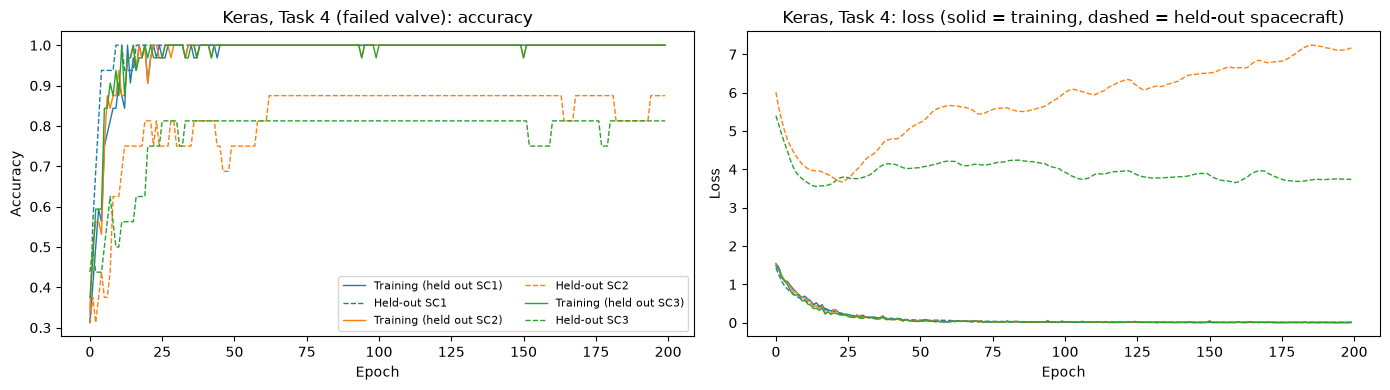

In [36]:
# -------------------------------------------------
# Learning curves (Lab 8): training vs held-out spacecraft, Task 4
# -------------------------------------------------
if HAVE_TF:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for sc, h in keras_histories['Task 4'].items():
        line, = axes[0].plot(h['accuracy'], lw=1, label=f'Training (held out SC{sc})')
        axes[0].plot(h['val_accuracy'], lw=1, ls='--', color=line.get_color(), label=f'Held-out SC{sc}')
        axes[1].plot(h['loss'], lw=1, color=line.get_color())
        axes[1].plot(h['val_loss'], lw=1, ls='--', color=line.get_color())
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_title('Keras, Task 4 (failed valve): accuracy')
    axes[0].legend(fontsize=8, ncol=2)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].set_title('Keras, Task 4: loss (solid = training, dashed = held-out spacecraft)')
    plt.tight_layout()
    savefig('keras_learning_curves_t4')
    plt.show()

In the learning curves the **training** accuracy reaches 100 % within about 25 epochs in every fold. When spacecraft 2 or 3
is held out, its accuracy levels off clearly lower and its loss (dashed) starts to **rise** again after about 25 epochs,
while the training loss keeps falling: with only 32 training cases per fold the network memorises the training spacecraft.
This is the typical sign of over-fitting described in Lab 8.

### 15.2 Neural network vs the best classical model

,Task,Metric,Keras,Best classical model,Best classical score
0,Task 1,Macro F1,0.971,Random Forest,1.000
1,Task 2,Macro F1,0.984,Random Forest,1.000
2,Task 3,Macro F1,0.919,Random Forest,1.000
3,Task 4,Macro F1,0.897,Random Forest,1.000
4,Task 5,MAE (%),14.814,Gradient Boosting,5.278


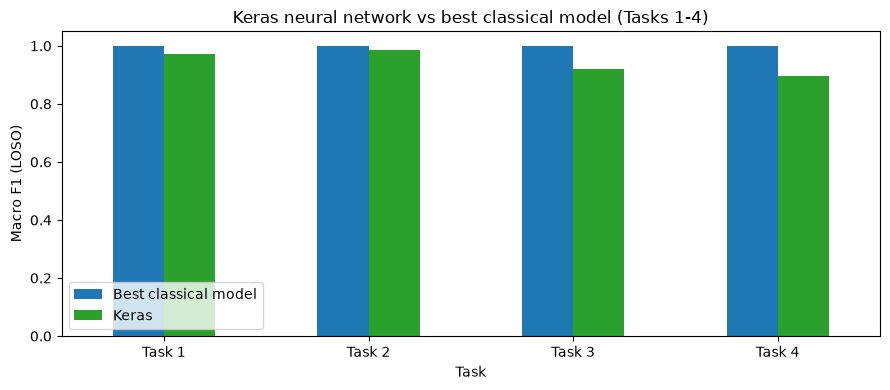

In [37]:
best_names = [RESULTS[t]['best'] for t in ['Task 1', 'Task 2', 'Task 3', 'Task 4']] + [best5]
best_scores = [RESULTS[t]['res'].loc[0, 'Macro F1'] for t in ['Task 1', 'Task 2', 'Task 3', 'Task 4']] + \
              [mean_absolute_error(y5, preds5[best5])]
nn_results['Best classical model'] = best_names
nn_results['Best classical score'] = best_scores

score_cols = ['Task', 'Metric'] + (['Keras'] if HAVE_TF else []) + \
             ['Best classical model', 'Best classical score']
display(nn_results[score_cols].round(3))
nn_results.to_csv(f'{OUT_DIR}/neural_network_comparison.csv', index=False)

# Bar chart for the classification tasks (Macro F1, higher is better)
plot_df = nn_results[nn_results['Metric'] == 'Macro F1'].set_index('Task')
plot_df = plot_df[['Best classical score'] + (['Keras'] if HAVE_TF else [])]
ax = plot_df.plot.bar(figsize=(9, 4), rot=0, color=['tab:blue', 'tab:green'][:plot_df.shape[1]])
ax.set_ylabel('Macro F1 (LOSO)')
ax.set_ylim(0, 1.05)
ax.set_title('Keras neural network vs best classical model (Tasks 1-4)')
ax.legend(['Best classical model', 'Keras'][:plot_df.shape[1]], loc='lower left')
plt.tight_layout()
savefig('neural_network_comparison')
plt.show()

**Conclusion on the neural network**

* **Computational cost is not a problem:** the Keras network trains in a few minutes for all tasks on an ordinary CPU.
* **Accuracy is the problem:** with only 24–177 training cases (and only two spacecraft per LOSO fold) the network fits
  the training spacecraft too closely and transfers less well to an unseen spacecraft than Random Forest. This is most
  visible for the small tasks (bubble location, failed valve) and for the opening-ratio regression.
* The neural network is therefore reported as part of the model comparison, but **the final models in Step 17 stay the
  classical ones** chosen in Steps 10–14. With many more training cases (or spacecraft) a neural network — for example a
  1-D convolutional network working directly on the raw signals — would become a realistic option.

## Step 16 — Summary of the model comparison

In [38]:
summary = pd.concat([RESULTS[t]['res'].assign(Task=t) for t in ['Task 1', 'Task 2', 'Task 3', 'Task 4']])
pivot = summary.pivot(index='Model', columns='Task', values='Macro F1').round(3)
pivot['Mean'] = pivot.mean(axis=1).round(3)
print('LOSO Macro F1 of every classifier on Tasks 1-4:')
display(pivot.sort_values('Mean', ascending=False))

final_table = pd.DataFrame([
    {'Task': 'Task 1', 'Chosen model': best1 + (' + novelty check'), 'LOSO score': f"Macro F1 = {f1_score(y1, or_pred, average='macro'):.3f}"},
    {'Task': 'Task 2', 'Chosen model': best2 + ' + novelty check', 'LOSO score': f"Macro F1 = {res2.loc[0, 'Macro F1']:.3f}"},
    {'Task': 'Task 3', 'Chosen model': best3, 'LOSO score': f"Macro F1 = {res3.loc[0, 'Macro F1']:.3f}"},
    {'Task': 'Task 4', 'Chosen model': best4, 'LOSO score': f"Macro F1 = {res4.loc[0, 'Macro F1']:.3f}"},
    {'Task': 'Task 5', 'Chosen model': best5, 'LOSO score': f"MAE = {mean_absolute_error(y5, preds5[best5]):.2f} %"},
])
display(final_table)

summary.to_csv(f'{OUT_DIR}/model_comparison_classification.csv', index=False)
res5.to_csv(f'{OUT_DIR}/model_comparison_regression.csv', index=False)

LOSO Macro F1 of every classifier on Tasks 1-4:


Task,Task 1,Task 2,Task 3,Task 4,Mean
Model,,,,,
Random Forest,1.000,1.000,1.000,1.000,1.000
Gradient Boosting,1.000,1.000,1.000,0.878,0.970
SVM (linear),0.965,0.984,0.919,0.958,0.956
SVM (RBF),0.931,0.984,0.877,0.857,0.912
KNN (k=3),0.988,1.000,0.835,0.767,0.898
Decision Tree,1.000,1.000,0.711,0.830,0.885
Gaussian NB,0.607,0.940,0.877,0.750,0.794


,Task,Chosen model,LOSO score
0,Task 1,Random Forest + novelty check,Macro F1 = 1.000
1,Task 2,Random Forest + novelty check,Macro F1 = 1.000
2,Task 3,Random Forest,Macro F1 = 1.000
3,Task 4,Random Forest,Macro F1 = 1.000
4,Task 5,Gradient Boosting,MAE = 5.28 %


## Step 17 — Final models and test-set predictions

All final models are refitted on **all** relevant training cases. The test cases are diagnosed hierarchically:

1. **Task 1** — classifier (+ novelty check) → normal / abnormal.
2. **Task 2** — only abnormal cases → bubble / valve; cases far from every known abnormal case → **unknown**.
3. **Task 3** — only bubble cases → location.
4. **Task 4** — only valve cases → failed valve; **Task 5** → opening ratio, using the predicted valve.

In [39]:
def fit_final(model, F, y):
    scaler = StandardScaler().fit(F)
    model.fit(scaler.transform(F), y)
    return scaler, model

def predict_final(fitted, F):
    scaler, model = fitted
    return model.predict(scaler.transform(F))

m1 = fit_final(get_classifiers()[best1], F1_, y1)
m2 = fit_final(get_classifiers()[best2], F2_, y2)
m3 = fit_final(get_classifiers()[best3], F3_, y3)
m4 = fit_final(get_classifiers()[best4], F4_, y4)
if USE_TUNED_RF:
    m5 = fit_final(RandomForestRegressor(random_state=RS, n_jobs=-1, **grid5.best_params_), F5_, y5)
else:
    m5 = fit_final(get_regressors()[best5], F5_, y5)
nov_normal = fit_novelty(F1_[~is_abn])          # normal-behaviour model (Task 1)
nov_known = fit_novelty(F2_)                     # known-anomaly model (Task 2)

F_te = F_test[FEATURES]
pred = test_labels.copy()

# ---------------- Task 1 ----------------
pred['task1'] = predict_final(m1, F_te)
pred['novelty_normal'] = novelty_score(nov_normal, F_te)
pred.loc[pred['novelty_normal'] > THR1, 'task1'] = 'abnormal'
abn = (pred['task1'] == 'abnormal').to_numpy()

# ---------------- Task 2 ----------------
pred['task2'] = None
pred['novelty_known'] = np.nan
if abn.any():
    pred.loc[abn, 'task2'] = predict_final(m2, F_te[abn])
    pred.loc[abn, 'novelty_known'] = novelty_score(nov_known, F_te[abn])
    pred.loc[abn & (pred['novelty_known'] > THR2).to_numpy(), 'task2'] = 'unknown'
bub = (pred['task2'] == 'bubble').to_numpy()
val = (pred['task2'] == 'valve').to_numpy()

# ---------------- Tasks 3, 4, 5 ----------------
pred['task3'] = None
pred['task4'] = None
pred['task5'] = np.nan
if bub.any():
    pred.loc[bub, 'task3'] = predict_final(m3, F_te[bub])
if val.any():
    pred.loc[val, 'task4'] = predict_final(m4, F_te[val])
    F5_te = add_valve_onehot(F_te[val], pred.loc[val, 'task4'].to_numpy())
    pred.loc[val, 'task5'] = np.clip(predict_final(m5, F5_te), 0, 100).round(1)

display(pred)

,case,spacecraft,task1,novelty_normal,task2,novelty_known,task3,task4,task5
0,178,1,abnormal,1244.808412,bubble,0.383199,BP2,None,NaN
1,179,1,abnormal,105.327434,valve,2.303592,None,SV2,23.9
2,180,1,normal,5.065748,None,NaN,None,None,NaN
3,181,1,abnormal,24.948560,valve,2.257077,None,SV4,75.3
4,182,1,normal,3.620034,None,NaN,None,None,NaN
5,183,1,normal,3.295708,None,NaN,None,None,NaN
6,184,1,abnormal,173936.841101,unknown,288.652197,None,None,NaN
7,185,1,normal,3.168485,None,NaN,None,None,NaN
8,186,1,abnormal,1302.938376,bubble,1.216068,BP6,None,NaN
9,187,1,normal,2.929023,None,NaN,None,None,NaN


In [40]:
# -----------------------------------------------------
# Sanity checks on the test predictions
# -----------------------------------------------------
print('Predicted condition per spacecraft:')
display(pd.crosstab(pred['spacecraft'], pred['task2'].fillna('normal')))

n_normal_sc4 = int(((pred['spacecraft'] == 4) & (pred['task1'] == 'normal')).sum())
n_sc4 = int((pred['spacecraft'] == 4).sum())
print(f'Spacecraft 4: {n_normal_sc4} of {n_sc4} cases predicted normal.')
print('The spacecraft-4 reference is the median of its test cases; this is reliable as long as most of them are normal.')

Predicted condition per spacecraft:


task2,bubble,normal,unknown,valve
spacecraft,,,,
1,5,11,3,4
4,5,12,3,3


Spacecraft 4: 12 of 23 cases predicted normal.
The spacecraft-4 reference is the median of its test cases; this is reliable as long as most of them are normal.


### 17.1 What do the test cases flagged as *unknown* look like?
Plotting their raw signals against a test case predicted as normal shows whether the novelty detector found something
physically different from the training anomalies.

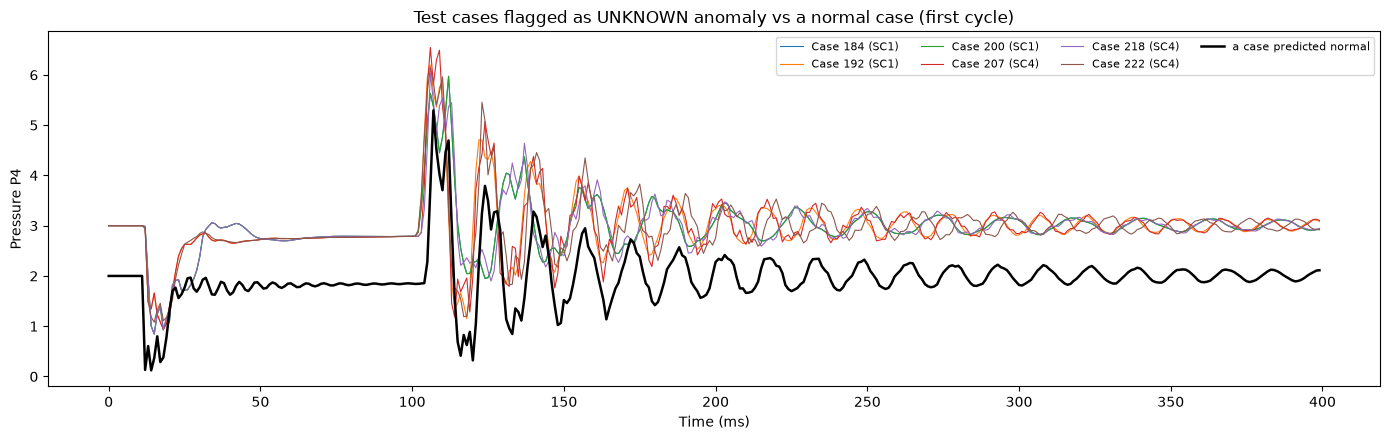

Pressure before the first valve opening (0-10 ms), mean over sensors:
  unknown cases: [3. 3. 3. 3. 3. 3.]
  normal cases : [2. 2. 2. 2. 2. 2.] ...
  training data: [2.]


In [41]:
unknown_idx = np.where(pred['task2'] == 'unknown')[0]
normal_idx = np.where(pred['task1'] == 'normal')[0]

if len(unknown_idx) > 0:
    fig, ax = plt.subplots(figsize=(14, 4.5))
    for i in unknown_idx:
        ax.plot(np.arange(CYCLE), X_test[i, 3, :CYCLE], lw=0.8,
                label=f"Case {pred.loc[i, 'case']} (SC{pred.loc[i, 'spacecraft']})")
    ax.plot(np.arange(CYCLE), X_test[normal_idx[0], 3, :CYCLE], 'k', lw=1.8, label='a case predicted normal')
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Pressure P4')
    ax.set_title('Test cases flagged as UNKNOWN anomaly vs a normal case (first cycle)')
    ax.legend(ncol=4, fontsize=8)
    plt.tight_layout()
    savefig('test_unknown_cases')
    plt.show()

    print('Pressure before the first valve opening (0-10 ms), mean over sensors:')
    print('  unknown cases:', X_test[unknown_idx, :, :10].mean(axis=(1, 2)).round(2))
    print('  normal cases :', X_test[normal_idx, :, :10].mean(axis=(1, 2)).round(2)[:6], '...')
    print('  training data:', np.unique(X_train[:, :, :10].mean(axis=(1, 2)).round(2)))

The unknown cases start from a clearly **higher initial (supply) pressure** than every training case, and the whole cycle is
shifted upward. This condition never appears in the training data, so neither a bubble nor a valve-fault label would be
correct — the novelty detector handles it as intended.

In [42]:
# -----------------------------------------------------
# Save the predictions
# -----------------------------------------------------
readable = pred.drop(columns=['novelty_normal', 'novelty_known'])
readable.to_csv(f'{OUT_DIR}/test_predictions_readable.csv', index=False)

# Numeric coding (edit the maps if the instructor's template uses a different coding)
submission = pd.DataFrame({
    'Spacecraft No': pred['spacecraft'],
    'Case No': pred['case'],
    'task1': (pred['task1'] == 'abnormal').astype(int),                          # 0 = normal, 1 = abnormal
    'task2': pred['task2'].map({'bubble': 1, 'valve': 2, 'unknown': 3}),         # 1 = bubble, 2 = SV fault, 3 = unknown
    'task3': pred['task3'].map({loc: i + 1 for i, loc in enumerate(BUBBLE_LOCS)}),  # 1 = BV1, 2 = BP1, ..., 8 = BP7
    'task4': pred['task4'].map({v: i + 1 for i, v in enumerate(VALVES)}),        # 1..4 = SV1..SV4
    'task5': pred['task5'],                                                      # opening ratio (%)
})
submission.to_csv(f'{OUT_DIR}/submission.csv', index=False)
print('Saved:', f'{OUT_DIR}/test_predictions_readable.csv', 'and', f'{OUT_DIR}/submission.csv')
display(submission.head(10))

Saved: outputs/test_predictions_readable.csv and outputs/submission.csv


,Spacecraft No,Case No,task1,task2,task3,task4,task5
0,1,178,1,1.0,3.0,NaN,NaN
1,1,179,1,2.0,NaN,2.0,23.9
2,1,180,0,NaN,NaN,NaN,NaN
3,1,181,1,2.0,NaN,4.0,75.3
4,1,182,0,NaN,NaN,NaN,NaN
5,1,183,0,NaN,NaN,NaN,NaN
6,1,184,1,3.0,NaN,NaN,NaN
7,1,185,0,NaN,NaN,NaN,NaN
8,1,186,1,1.0,7.0,NaN,NaN
9,1,187,0,NaN,NaN,NaN,NaN


## Step 18 — Interactive dashboard (Bokeh, Lab 3)

The dashboard shows the class-mean signal of any sensor (raw or residual) selected from a dropdown, together with summary
statistics of the dataset, the chosen models and the test predictions. It is displayed in the notebook and also saved as
`outputs/dashboard.html`.

In [43]:
from bokeh.io import output_notebook, show, output_file, save
from bokeh.plotting import figure
from bokeh.models import ColumnDataSource, Select, CustomJS, Div
from bokeh.layouts import row, column

output_notebook()

# -----------------------------------------------------
# Data: class-mean cycle signal of every sensor, raw and residual
# -----------------------------------------------------
conds = list(COND_COLORS)
t_cycle = np.arange(CYCLE)
all_data = {'t': t_cycle}
options = []
for k, s in enumerate(SENSORS):
    for kind, arr in [('raw', C_train), ('residual', R_train)]:
        key = f'{s} {kind}'
        options.append(key)
        for c in conds:
            all_data[f'{key}|{c}'] = arr[(train_labels['condition'] == c).to_numpy(), k].mean(axis=0)

source = ColumnDataSource(data={'t': t_cycle, **{c: all_data[f'P1 raw|{c}'] for c in conds}})
full = ColumnDataSource(data=all_data)

p = figure(title='Class-mean pressure over one valve cycle', x_axis_label='Time within cycle (ms)',
           y_axis_label='Pressure', width=750, height=380)
for c in conds:
    p.line(x='t', y=c, source=source, color=COND_COLORS[c].replace('tab:', ''), line_width=2, legend_label=c)

# -----------------------------------------------------
# Dropdown
# -----------------------------------------------------
dropdown = Select(title='Select sensor and signal type:', value='P1 raw', options=options)
callback = CustomJS(args=dict(source=source, full=full, conds=conds), code='''
    const key = cb_obj.value;
    for (const c of conds) { source.data[c] = full.data[key + '|' + c]; }
    source.change.emit();
''')
dropdown.js_on_change('value', callback)

# -----------------------------------------------------
# Statistics
# -----------------------------------------------------
counts = train_labels['condition'].value_counts()
stats_data = Div(text=f'''
    <h3>Dataset</h3>
    Training cases = {len(train_labels)}<br>
    normal = {counts['normal']}, bubble = {counts['bubble']}, valve = {counts['valve']}<br>
    Test cases = {len(test_labels)} (SC1 = {np.sum(sc_test == 1)}, SC4 = {np.sum(sc_test == 4)})<br>
    Features used = {len(FEATURES)} ({best_set})
''', width=260)

stats_models = Div(text='<h3>Chosen models (LOSO)</h3>' +
                   '<br>'.join(f"{r['Task']}: {r['Chosen model']}<br>&nbsp;&nbsp;{r['LOSO score']}"
                               for _, r in final_table.iterrows()), width=300)

pc = pred['task2'].fillna('normal').value_counts()
stats_pred = Div(text='<h3>Test predictions</h3>' + '<br>'.join(f'{k} = {v}' for k, v in pc.items()), width=200)

dashboard = column(row(stats_data, stats_models, stats_pred), row(dropdown, p))
show(dashboard)

output_file(f'{OUT_DIR}/dashboard.html', title='MEF321 Propulsion PHM Dashboard')
save(dashboard)
print('Dashboard saved to', f'{OUT_DIR}/dashboard.html')

Loading BokehJS ...

Dashboard saved to outputs/dashboard.html


## Step 19 — Conclusions and notes for the report

* **Pre-processing matters most.** Averaging the three valve cycles reduces noise, and subtracting a spacecraft reference
  signal (median of that spacecraft's cases) removes the individual differences between spacecraft. With raw features the
  models partly learn *which spacecraft* a case comes from; with residual features they learn *the condition*. This is what
  makes the models transfer to the unseen spacecraft 4 (see Steps 8.4 and 9.3).
* **Validation:** Leave-One-Spacecraft-Out is the right validation for this problem. A random split mixes spacecraft and is
  optimistic (Step 9.2).
* **Features:** physically motivated statistics of four phases of the valve cycle (opening, flow, water hammer, decaying
  oscillation), FFT dominant frequency (bubble → lower speed of sound) and the share of residual energy per sensor (location).
* **Models:** seven classifiers from Labs 6–8 were compared on identical LOSO folds; the best model per task is selected by
  macro F1 (ties broken by worst-spacecraft accuracy). Task 5 uses regression versions of the same models, tuned with
  `GridSearchCV` on the LOSO folds.
* **Neural network:** a Keras network (Lab 8) is affordable to train on a CPU, but with so few training cases it
  generalises to an unseen spacecraft less well than Random Forest (Step 15), so they are not used for the final predictions.
* **Unknown anomalies:** a distance-to-nearest-known-cases novelty score in PCA space. A simulated new anomaly type (hidden
  bubbles) is detected reliably; hidden mild valve faults are harder because they resemble normal behaviour.

**Limitations**

* Very few cases for Task 3 (3 per location) — the LOSO score is based on only 24 predictions.
* Training opening ratios are only 0/25/50/75 %; ratios in between (or above 75 %) must be interpolated by the model.
* The spacecraft-4 reference assumes that most of its test cases are normal (checked in Step 17).
* Task 5 depends on Task 4: a wrong valve prediction also affects the ratio prediction.